# 08 — Midterm report: every result, table, and figure

This notebook produces **all numbers, tables, and figures for the midterm report** from the finished runs.
Run it once from top to bottom on CARC. Nothing here trains a model or needs a GPU.

**What it reads:** `group26/artifacts/runs` (every method) and `group26/artifacts/joint_runs` (joint training).

**How to use it**

1. In the settings cell, comment out any method you do not want (for example `# 'dapr_weak',`), then
   **Run All**. Every table, figure, and number is rebuilt without it.
2. Look at the figures and tables. **Nothing is saved automatically.**
3. Keep what you like with `save(...)` in any cell, at any time:
   - `save('F1')`: one figure (PNG at 300 dpi + PDF). `save('T1')`: one table (CSV).
   - `save('F1', 'F5', 'T1', 'T5')`: several at once. `save('key_numbers')`: the numbers for the text.
   - `save('all')`: everything. `list_outputs()` shows every name.
   - `zip_saved()`: one zip of everything saved so far, to download.

Saved files go to `group26/artifacts/analysis/midterm/` (`figures/`, `tables/`).

**Where each output goes in the report:** see the last section, "Report map".

All results use the **validation split** (200 pairs per behavior) on the **8 development cells**
(orders 1–4 × seeds 0–1). The locked test set is not touched.

## 0. Settings

Edit only this cell, then Run All.

- **`METHODS`**: comment a line out to drop that method from every table and figure. No replay and
  Random 10% must stay (they are the reference and the baseline). A method also needs all 8 cells to
  appear (set `ALLOW_PARTIAL = True` to show incomplete ones anyway).
- **`INCLUDE_JOINT`**: set to `False` to hide joint training and the gap-closed column.

In [1]:
import json, os, shutil, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import HTML, display

ARTIFACTS = Path(os.environ.get('MFR_OUTPUT_DIR', '/project2/xiangren_1987/group26/artifacts'))

# ---- Methods to show: comment out a line to drop that method everywhere ----
METHODS = [
    'none',              # No replay (required)
    'random',            # Random 10% (required, the equal-budget baseline)
    'random_high',       # Random 14.3%
    'mfr',               # MFR (ours)
   # 'mfr_balanced',      # Balanced MFR
   # 'mfr_at_risk',       # At-Risk MFR
   # 'mfr_stochastic',    # Stochastic MFR (skipped automatically until all 8 cells exist)
    'lowest_margin',     # Lowest margin
   # 'dapr_weak',         # DAPR-weak
]
INCLUDE_JOINT = True     # joint-training reference and "gap closed" column

EXTENSION_METHODS = ['dapr_weak']      # changes the training loss, not only the selection; flagged in tables
ORDERS = [1, 2, 3, 4]
SEEDS = [0, 1]
SPLIT = 'val'                          # never 'test' before the method is frozen
SCORE = 'accuracy'                     # primary metric; 'accuracy_sum' is the secondary one
MARGIN_COL = 'margin' if SCORE == 'accuracy' else 'margin_sum'
BASELINE = 'random'                    # all "vs" comparisons use equal-budget Random 10%
TOLERANCE = 2.0                        # final-task points a method may lose vs Random 10%
N_BOOT = 20000                         # bootstrap resamples over order-seed cells
BOOT_SEED = 544
ALLOW_PARTIAL = False
EXAMPLE_CELL = (1, 0)                  # (order, seed) used for the Safety example in the introduction
OUT = ARTIFACTS / 'analysis' / 'midterm'      # where save(...) writes

REPO = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'configs/experiment_protocol.json').exists()), None)
PROTOCOL = json.loads((REPO / 'configs/experiment_protocol.json').read_text()) if REPO else {}
if PROTOCOL:
    TOLERANCE = float(PROTOCOL.get('new_learning_tolerance_points', TOLERANCE))
    PROTOCOL_ORDERS = {int(k): list(v) for k, v in PROTOCOL['orders'].items()}
else:
    PROTOCOL_ORDERS = {}
print('artifacts:', ARTIFACTS, '| exists:', ARTIFACTS.exists())
print('methods  :', ', '.join(METHODS))
print('save(...) writes to:', OUT)

artifacts: /project2/xiangren_1987/group26/artifacts | exists: True
methods  : none, random, random_high, mfr, lowest_margin
save(...) writes to: /project2/xiangren_1987/group26/artifacts/analysis/midterm


### Labels, colors, and plot style

Colors follow one rule: a method keeps the same color in every figure. Random 14.3% is a lighter
step of Random 10%'s blue because it is the same rule with more slots. Every bar and point also has a
text label, so no result depends on color alone.

In [2]:
MLABEL = {'none': 'No replay', 'random': 'Random 10%', 'random_high': 'Random 14.3%',
          'lowest_margin': 'Lowest margin', 'mfr': 'MFR (ours)', 'mfr_balanced': 'Balanced MFR',
          'mfr_at_risk': 'At-Risk MFR', 'mfr_stochastic': 'Stochastic MFR', 'dapr_weak': 'DAPR-weak',
          'joint': 'Joint training'}
MCOLOR = {'none': '#8a8984', 'random': '#2a78d6', 'random_high': '#86b6ef', 'lowest_margin': '#1baf7a',
          'mfr': '#eb6834', 'mfr_balanced': '#eda100', 'mfr_at_risk': '#e87ba4', 'mfr_stochastic': '#e34948',
          'dapr_weak': '#6250d6', 'joint': '#0b0b0b'}
DATASETS = ['helpful', 'safe', 'quality']
DLABEL = {'helpful': 'Helpful', 'safe': 'Safe', 'quality': 'Quality'}
DCOLOR = {'helpful': '#2a78d6', 'safe': '#eb6834', 'quality': '#1baf7a'}
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e5e4e0'
FORGET_C, RECOVER_C, NEUTRAL = '#e34948', '#2a78d6', '#f0efec'
DIVERGING = LinearSegmentedColormap.from_list('div', [FORGET_C, NEUTRAL, RECOVER_C])
SEQUENTIAL = LinearSegmentedColormap.from_list('seq', ['#cde2fb', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])
KEY_METHODS = ['none', 'random', 'mfr', 'lowest_margin', 'dapr_weak']   # for line charts (fewer series)

def _report_font():
    """Use Calibri/Carlito (the report's font). Carlito is free; download it once if missing."""
    from matplotlib import font_manager as fm
    have = {f.name for f in fm.fontManager.ttflist}
    for name in ['Calibri', 'Carlito']:
        if name in have:
            return name
    cache = Path.home() / '.cache' / 'mfr_fonts'
    try:
        import urllib.request
        cache.mkdir(parents=True, exist_ok=True)
        for style in ['Regular', 'Bold', 'Italic', 'BoldItalic']:
            path = cache / f'Carlito-{style}.ttf'
            if not path.exists():
                urllib.request.urlretrieve(f'https://github.com/google/fonts/raw/main/ofl/carlito/{path.name}', path)
            fm.fontManager.addfont(str(path))
        return 'Carlito'
    except Exception as error:
        print(f'Carlito not available ({error}); using DejaVu Sans.')
        return 'DejaVu Sans'

FONT = _report_font()
plt.rcParams.update({
    'font.family': FONT, 'font.size': 9.5, 'axes.titlesize': 9.5, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlepad': 6, 'axes.labelsize': 9.5, 'xtick.labelsize': 8.5,
    'ytick.labelsize': 9, 'legend.fontsize': 8.5, 'legend.frameon': False, 'legend.handlelength': 1.4,
    'legend.columnspacing': 1.2, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8a8984', 'axes.linewidth': 0.8, 'axes.labelcolor': INK, 'xtick.color': INK2,
    'ytick.color': INK, 'xtick.major.size': 3, 'ytick.major.size': 0, 'text.color': INK,
    'grid.color': GRID, 'grid.linewidth': 0.7, 'lines.linewidth': 2, 'lines.markersize': 5,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.constrained_layout.use': True, 'pdf.fonttype': 42, 'ps.fonttype': 42,
})
FULL_W, HALF_W = 6.5, 3.25   # inches: full text width of the report, and half of it
print('Figure font:', FONT)

def num(value, digits=2, sign=False):
    """Number with a real minus sign (looks right in print)."""
    text = f'{value:+.{digits}f}' if sign else f'{value:.{digits}f}'
    return text.replace('-', '−')

display(HTML('''<style>.rt{border-collapse:collapse;font-size:12.5px;margin:6px 0 14px}
.rt th{background:#333;color:#fff;padding:5px 9px;text-align:left}
.rt td{padding:4px 9px;border-bottom:1px solid #ddd}</style>'''))

FIGURES, TABLES, TEXTS, CAPTIONS = {}, {}, {}, {}   # everything shown so far; save(...) writes from here

def show(df, name=None, caption=None, decimals=2):
    """Display a table (not saved; use save('T1') to keep it)."""
    out = df.copy()
    nums = out.select_dtypes(include='number').columns
    out[nums] = out[nums].round(decimals)
    label = f'[{name.split("_")[0]}] ' if name else ''
    if caption:
        display(HTML(f'<b>{label}{caption}</b>'))
    display(HTML(out.to_html(index=False, border=0, na_rep='—', classes='rt')))
    if name:
        TABLES[name] = out

def show_fig(fig, name, caption=''):
    """Display a figure with a suggested caption (not saved; use save('F1') to keep it)."""
    FIGURES[name] = fig
    CAPTIONS[name] = caption
    tag = name.split('_')[0]
    display(fig)
    plt.close(fig)
    display(HTML(f'<div style="max-width:900px;font-size:12.5px;color:#888;margin:2px 0 18px">'
                 f'<b>{tag}</b> &nbsp;suggested caption: {caption} &nbsp;&nbsp;'
                 f'<code>save(\'{tag}\')</code> keeps it.</div>'))

def _match(key, names):
    tag = key.split('_')[0]          # e.g. 'F1', 'T2a', 'key'
    return any(n == 'all' or key == n or tag == n or key.startswith(n + '_')
               or (tag.startswith(n) and tag[len(n):].isalpha()) for n in names)   # 'T2' -> T2a and T2b

def save(*names):
    """save('F1'), save('T1'), save('F1', 'T5'), save('key_numbers'), save('figures'), save('tables'), save('all')."""
    names = [str(n) for n in names] or ['all']
    figs = FIGURES if ('figures' in names) else {k: v for k, v in FIGURES.items() if _match(k, names)}
    tabs = TABLES if ('tables' in names) else {k: v for k, v in TABLES.items() if _match(k, names)}
    txts = {k: v for k, v in TEXTS.items() if _match(k, names)}
    if not (figs or tabs or txts):
        print('Nothing matched', names, '- run list_outputs() to see the names.')
        return
    for k, fig in figs.items():
        (OUT / 'figures').mkdir(parents=True, exist_ok=True)
        fig.savefig(OUT / 'figures' / f'{k}.png', bbox_inches='tight', pad_inches=0.04)
        fig.savefig(OUT / 'figures' / f'{k}.pdf', bbox_inches='tight', pad_inches=0.04)
        if CAPTIONS.get(k):
            (OUT / 'figures' / f'{k}_caption.txt').write_text(CAPTIONS[k] + '\n')
        print('saved', OUT / 'figures' / f'{k}.png', '(+ .pdf, caption)')
    for k, df in tabs.items():
        (OUT / 'tables').mkdir(parents=True, exist_ok=True)
        df.to_csv(OUT / 'tables' / f'{k}.csv', index=False)
        print('saved', OUT / 'tables' / f'{k}.csv')
    for k, text in txts.items():
        OUT.mkdir(parents=True, exist_ok=True)
        (OUT / f'{k}.txt').write_text(text + '\n')
        print('saved', OUT / f'{k}.txt')

def list_outputs():
    for kind, items in [('Figures', FIGURES), ('Tables', TABLES), ('Text', TEXTS)]:
        print(f'{kind}:')
        tags = [k.split('_')[0] for k in items]
        for k, tag in zip(items, tags):
            short = tag if (kind != 'Text' and tags.count(tag) == 1) else k
            print(f"   save('{short}')".ljust(26) + f'->  {k}')

def zip_saved():
    if not OUT.exists():
        print('Nothing saved yet.')
        return
    archive = shutil.make_archive(str(OUT.parent / 'midterm_outputs'), 'zip', OUT)
    print('Zip:', archive)
    print(f'Download from your laptop:  scp <user>@discovery.usc.edu:{archive} ~/Downloads/')

def clean_axis(ax, grid='x'):
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.7)
        ax.set_axisbelow(True)

def no_frame(ax):
    for side in ax.spines.values():
        side.set_visible(False)
    ax.tick_params(length=0)

def method_axis(ax, methods):
    """Method names on the y axis, worst at the top, no left spine."""
    ax.set_yticks(range(len(methods)), [MLABEL[m] for m in methods])
    ax.set_ylim(len(methods) - 0.5, -0.7)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0)

Figure font: Carlito


## 1. Load the runs

A run is used only when its folder has `COMPLETE.json`, `settings.json`, and `results.csv`.
Methods other than No replay reuse the No replay run's Stage-1 model (`stage1_from`), so Stage 1 is
read from that run.

In [3]:
def read_json(path):
    return json.loads(Path(path).read_text())

def scan_runs(root):
    found = []
    runs_dir = Path(root) / 'runs'
    if not runs_dir.exists():
        return found
    for folder in sorted(runs_dir.glob('*')):
        needed = [folder / 'COMPLETE.json', folder / 'settings.json', folder / 'results.csv']
        if not all(p.exists() for p in needed):
            continue
        s = read_json(folder / 'settings.json')
        method = str(s.get('method'))
        if method not in METHODS:
            continue
        order_id, seed = int(s['order_id']), int(s['seed'])
        if order_id not in ORDERS or seed not in SEEDS:
            continue
        found.append({'run_name': s.get('run_name', folder.name), 'method': method, 'order_id': order_id,
                      'seed': seed, 'order': list(s['order']), 'folder': folder,
                      'stage1_from': s.get('stage1_from'),
                      'protocol_version': str(s.get('protocol_version')), 'data_version': str(s.get('data_version')),
                      'model_revision': str(s.get('model_revision'))})
    return found

for need in ['none', BASELINE]:
    assert need in METHODS, f"'{need}' is required; do not comment it out"
records = {(r['method'], r['order_id'], r['seed']): r for r in scan_runs(ARTIFACTS)}
if not records:
    raise FileNotFoundError(f'No completed runs found under {ARTIFACTS}/runs')

inventory = (pd.DataFrame(list(records.values()))
             .groupby('method').agg(cells=('run_name', 'count'),
                                    protocol=('protocol_version', lambda s: ', '.join(sorted(set(s)))),
                                    data=('data_version', lambda s: ', '.join(sorted(set(s)))))
             .reindex(METHODS).dropna(how='all').reset_index())
inventory['complete'] = inventory['cells'] == len(ORDERS) * len(SEEDS)
show(inventory.assign(method=inventory['method'].map(MLABEL)), 'T00_inventory', 'Runs found per method')

USED = [m for m in METHODS if m in set(inventory.loc[inventory['complete'] | ALLOW_PARTIAL, 'method'])]
missing = [m for m in METHODS if m not in USED]
print('Methods used:', ', '.join(MLABEL[m] for m in USED))
if missing:
    print('Not used (fewer than 8 cells or not found):', ', '.join(MLABEL[m] for m in missing))
for need in ['none', BASELINE]:
    assert need in USED, f'{MLABEL[need]} must have all 8 cells'
records = {k: v for k, v in records.items() if k[0] in USED}
for rec in records.values():
    if PROTOCOL_ORDERS:
        assert rec['order'] == PROTOCOL_ORDERS[rec['order_id']], f"order mismatch in {rec['run_name']}"

method,cells,protocol,data,complete
No replay,8,2.1,v2,True
Random 10%,8,2.1,v2,True
Random 14.3%,8,2.1,v2,True
MFR (ours),8,2.1,v2,True
Lowest margin,8,2.1,v2,True


Methods used: No replay, Random 10%, Random 14.3%, MFR (ours), Lowest margin


### 1.1 Are the comparisons fair?

Three checks before any number is trusted:

1. Every run uses the same data version and model revision.
2. Every method in a cell starts from the **identical Stage-1 model**: its Stage-1 validation margins
   must match the No replay run of that cell. This matters most for runs trained in the extended folder
   and copied here (for example DAPR-weak).
3. The accuracy recomputed from the pair-level margins equals `results.csv` (checked in section 5).

In [4]:
def stage_dir(rec, stage):
    d = rec['order'][stage - 1]
    direct = rec['folder'] / f'stage{stage}_{d}'
    if direct.exists() or stage != 1 or not rec['stage1_from']:
        return direct
    source = Path(rec['stage1_from'])
    if not source.exists():
        source = rec['folder'].parent / source.name
    return source / f'stage1_{d}'

def margins(rec, stage, dataset):
    path = stage_dir(rec, stage) / f'margins_{dataset}_{SPLIT}.csv'
    return pd.read_csv(path)

meta = pd.DataFrame(list(records.values()))
for column in ['data_version', 'model_revision', 'protocol_version']:
    values = sorted(meta[column].unique())
    flag = 'OK' if len(values) == 1 else 'CHECK: mixed values'
    print(f'{column:17s}: {values}  -> {flag}')

stage1_rows = []
for (method, order_id, seed), rec in records.items():
    if method == 'none':
        continue
    base = records[('none', order_id, seed)]
    first = rec['order'][0]
    a = margins(rec, 1, first)[['id', MARGIN_COL]].rename(columns={MARGIN_COL: 'margin'})
    b = margins(base, 1, first)[['id', MARGIN_COL]].rename(columns={MARGIN_COL: 'margin'})
    q = a.merge(b, on='id', suffixes=('', '_none'))
    stage1_rows.append({'method': method, 'order_id': order_id, 'seed': seed,
                        'pairs_matched': len(q), 'max_abs_margin_diff': float((q['margin'] - q['margin_none']).abs().max())})
stage1_check = pd.DataFrame(stage1_rows)
bad = stage1_check[(stage1_check['max_abs_margin_diff'] > 1e-4) | (stage1_check['pairs_matched'] < 200)]
summary_check = (stage1_check.groupby('method').agg(cells=('seed', 'count'), worst_diff=('max_abs_margin_diff', 'max'))
                 .reindex(USED).dropna().reset_index())
show(summary_check.assign(method=summary_check['method'].map(MLABEL)), 'T00_stage1_check',
     'Stage-1 identity check (worst difference from the No replay Stage-1 margins)', decimals=6)
if len(bad):
    warnings.warn(f'{len(bad)} runs do NOT share the No replay Stage-1 model. Inspect `bad` before reporting.')
    display(bad)
else:
    print('All methods share the identical Stage-1 model in every cell.')

data_version     : ['v2']  -> OK
model_revision   : ['989aa7980e4cf806f80c7fef2b1adb7bc71aa306']  -> OK
protocol_version : ['2.1']  -> OK


method,cells,worst_diff
Random 10%,8.0,0.0
Random 14.3%,8.0,0.0
MFR (ours),8.0,0.0
Lowest margin,8.0,0.0


All methods share the identical Stage-1 model in every cell.


## 2. Per-run summary

For each run (one method in one order–seed cell):

- **Old-behavior change (retention):** for each of the first two behaviors, final accuracy minus
  accuracy right after it was learned; averaged over the two. Closer to 0 is better.
- **Final task:** accuracy on the behavior learned last (new learning).
- **Final average:** mean final accuracy over Helpful, Safe, and Quality (the overall score).

In [5]:
results = {key: pd.read_csv(rec['folder'] / 'results.csv') for key, rec in records.items()}

def acc(frame, stage, dataset, score=SCORE):
    row = frame[(frame['stage'] == stage) & (frame['eval_set'] == dataset)]
    return float(row.iloc[0][score]) if len(row) else np.nan

run_rows, behavior_rows = [], []
for (method, order_id, seed), rec in records.items():
    frame, order, last = results[(method, order_id, seed)], rec['order'], len(rec['order'])
    changes = []
    for learned_at, d in enumerate(order[:-1], 1):
        learned, final = acc(frame, learned_at, d), acc(frame, last, d)
        changes.append(final - learned)
        behavior_rows.append({'method': method, 'order_id': order_id, 'seed': seed, 'dataset': d,
                              'learned_at': learned_at, 'learned': learned, 'final': final, 'change': final - learned})
    finals = {d: acc(frame, last, d) for d in DATASETS}
    gains = [acc(frame, s, d) - acc(frame, s - 1, d) for s, d in enumerate(order, 1)]
    run_rows.append({'method': method, 'order_id': order_id, 'seed': seed, 'old_change': np.mean(changes),
                     'worst_change': np.min(changes), 'final_task': finals[order[-1]],
                     'final_average': np.mean(list(finals.values())), 'mean_stage_gain': np.mean(gains),
                     **{f'final_{d}': finals[d] for d in DATASETS}})
per_run = pd.DataFrame(run_rows)
per_behavior = pd.DataFrame(behavior_rows)

def wide(metric, frame=None):
    frame = per_run if frame is None else frame
    return frame.pivot_table(index=['order_id', 'seed'], columns='method', values=metric).reindex(columns=USED)

## 3. Joint training (upper reference)

Joint training learns all three behaviors together in one stage, so nothing is forgotten by design.
It gives the best final average we could hope for and lets us report the **share of the gap closed**:
`(method − No replay) / (Joint − No replay)` on the final average.

In [6]:
joint_rows = []
for root in ([ARTIFACTS] if INCLUDE_JOINT else []):
    candidates = sorted((root / 'joint_runs').glob('*')) if (root / 'joint_runs').exists() else []
    if (root / 'runs').exists():
        candidates += [p for p in sorted((root / 'runs').glob('*joint*'))]
    for folder in candidates:
        if not ((folder / 'results.csv').exists() and (folder / 'COMPLETE.json').exists()):
            continue
        s = read_json(folder / 'settings.json') if (folder / 'settings.json').exists() else {}
        frame = pd.read_csv(folder / 'results.csv')
        last = int(frame['stage'].max())
        seed = int(s.get('seed', frame['seed'].iloc[0] if 'seed' in frame else -1))
        finals = {d: acc(frame, last, d) for d in DATASETS}
        joint_rows.append({'run': folder.name, 'seed': seed, **finals, 'final_average': np.mean(list(finals.values()))})
joint = pd.DataFrame(joint_rows).drop_duplicates('seed') if joint_rows else pd.DataFrame()
if len(joint):
    matched = joint[joint['seed'].isin(SEEDS)]
    if len(matched):
        joint = matched
    else:
        warnings.warn('No joint run with seeds 0-1; using all joint seeds found.')
    show(joint, 'T00_joint_runs', 'Joint-training runs used')
    JOINT_AVG = float(joint['final_average'].mean())
    JOINT_BY_D = {d: float(joint[d].mean()) for d in DATASETS}
else:
    JOINT_AVG, JOINT_BY_D = np.nan, {}
    print('Joint training not shown.' if not INCLUDE_JOINT else 'No joint runs found; gap-closed columns will be empty.')

run,seed,helpful,safe,quality,final_average
v2_joint_s0,0,66.5,82.5,73.5,74.17
v2_joint_s1,1,68.0,81.5,72.0,73.83


## 4. Main results (Report §4.3, Table 1)

Means over the 8 cells, sorted **worst to best** by old-behavior change. Brackets are 95% paired
bootstrap intervals over cells for the difference from Random 10% (20,000 resamples). "Cells better"
counts the cells (out of 8) where the method forgot less than Random 10% in the same cell.

In [7]:
def boot_mean(values, seed=BOOT_SEED):
    v = np.asarray(values, float)
    v = v[~np.isnan(v)]
    rng = np.random.default_rng(seed)
    samples = v[rng.integers(0, len(v), size=(N_BOOT, len(v)))].mean(axis=1)
    lo, hi = np.quantile(samples, [0.025, 0.975])
    return v.mean(), lo, hi

def paired(metric, a, b, seed=BOOT_SEED, frame=None):
    w = wide(metric, frame)
    d = (w[a] - w[b]).dropna().to_numpy()
    mean, lo, hi = boot_mean(d, seed)
    return {'diff': mean, 'lo': lo, 'hi': hi, 'better': int((d > 1e-9).sum()), 'tied': int((np.abs(d) <= 1e-9).sum()),
            'worse': int((d < -1e-9).sum()), 'n': len(d)}

means = per_run.groupby('method')[['old_change', 'worst_change', 'final_task', 'final_average']].mean().reindex(USED)
base_change = means.loc[BASELINE, 'old_change']
none_avg = means.loc['none', 'final_average']
rows = []
for i, m in enumerate(USED):
    r = paired('old_change', m, BASELINE, BOOT_SEED + i) if m != BASELINE else None
    rows.append({'key': m, 'Method': MLABEL[m] + (' †' if m in EXTENSION_METHODS else ''),
                 'Old-behavior change': means.loc[m, 'old_change'],
                 'Less forgetting than Random 10% (%)': 100 * (means.loc[m, 'old_change'] - base_change) / abs(base_change),
                 'Δ retention vs Random 10%': r['diff'] if r else np.nan,
                 '95% low': r['lo'] if r else np.nan, '95% high': r['hi'] if r else np.nan,
                 'Cells better (of 8)': f"{r['better']}/{r['n']}" if r else '—',
                 'Final task': means.loc[m, 'final_task'],
                 'Δ final task vs Random 10%': means.loc[m, 'final_task'] - means.loc[BASELINE, 'final_task'],
                 'Final average': means.loc[m, 'final_average'],
                 'Gap closed to Joint (%)': 100 * (means.loc[m, 'final_average'] - none_avg) / (JOINT_AVG - none_avg)
                 if np.isfinite(JOINT_AVG) and JOINT_AVG != none_avg else np.nan})
table1 = pd.DataFrame(rows).sort_values('Old-behavior change').reset_index(drop=True)
if np.isfinite(JOINT_AVG):
    table1 = pd.concat([table1, pd.DataFrame([{'key': 'joint', 'Method': 'Joint training (reference)',
                                               'Final average': JOINT_AVG, 'Gap closed to Joint (%)': 100.0}])], ignore_index=True)
show(table1.drop(columns='key'), 'T1_main_results',
     'Table 1. Main results (validation, 8 cells). † = changes the replay loss, not only the selection.')

Method,Old-behavior change,Less forgetting than Random 10% (%),Δ retention vs Random 10%,95% low,95% high,Cells better (of 8),Final task,Δ final task vs Random 10%,Final average,Gap closed to Joint (%)
No replay,-7.94,-44.32,-2.44,-3.47,-1.44,0/8,74.81,1.19,70.77,0.00
Random 10%,-5.50,0.00,—,—,—,—,73.62,0.00,71.71,29.03
Random 14.3%,-5.47,0.57,0.03,-0.53,0.50,4/8,73.88,0.25,71.73,29.68
MFR (ours),-4.88,11.36,0.62,0.22,1.09,7/8,73.75,0.12,71.98,37.42
Lowest margin,-4.47,18.75,1.03,0.44,1.47,7/8,74.31,0.69,72.56,55.48
Joint training (reference),—,—,—,—,—,—,—,—,74.00,100.00


### Figure 1: forgetting per method, worst to best

Bars show mean old-behavior change; whiskers are 95% bootstrap intervals over the 8 cells. The dashed
line marks Random 10%, the equal-budget baseline.

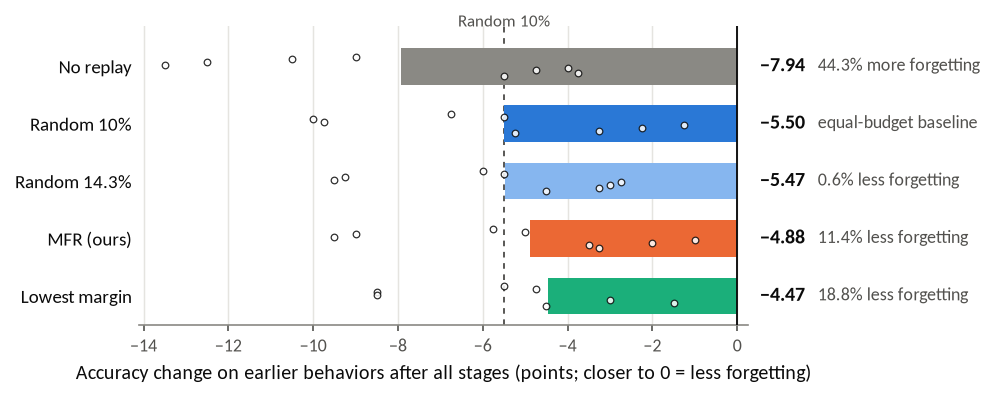

In [8]:
order_methods = list(table1.loc[table1['key'] != 'joint', 'key'])
cell_values = wide('old_change')
fig, ax = plt.subplots(figsize=(FULL_W, 0.36 * len(order_methods) + 0.75))
for y, m in enumerate(order_methods):
    mean = means.loc[m, 'old_change']
    ax.barh(y, mean, height=0.64, color=MCOLOR[m], zorder=2)
    pts = cell_values[m].dropna().to_numpy()
    ax.scatter(pts, y + np.linspace(-0.17, 0.17, len(pts)), s=10, color='white', edgecolor=INK,
               linewidth=0.6, alpha=0.85, zorder=3)
    pct = 100 * (mean - base_change) / abs(base_change)
    note = 'equal-budget baseline' if m == BASELINE else (f'{pct:.1f}% less forgetting' if pct >= 0 else f'{-pct:.1f}% more forgetting')
    ax.text(1.02, y, num(mean), transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=9.5, fontweight='bold')
    ax.text(1.115, y, note, transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=8.5, color=INK2)
ax.axvline(base_change, color=INK2, lw=0.9, ls=(0, (3, 3)), zorder=1)
ax.text(base_change, -0.62, 'Random 10%', ha='center', va='bottom', fontsize=8, color=INK2)
ax.axvline(0, color=INK, lw=0.9, zorder=4)
method_axis(ax, order_methods)
ax.set_xlim(np.nanmin(cell_values.to_numpy()) - 0.6, 0.25)
ax.set_xlabel('Accuracy change on earlier behaviors after all stages (points; closer to 0 = less forgetting)')
clean_axis(ax, 'x')
show_fig(fig, 'F1_forgetting_by_method',
         f'Forgetting of earlier behaviors per method, worst to best. Bars: mean over {len(ORDERS) * len(SEEDS)} order–seed cells; '
         'dots: individual cells. Right: change relative to equal-budget Random 10% replay.')

### Figure 2: retention vs new learning (the trade-off)

A method that forgets less but blocks new learning is not useful. Each point is a method's mean over
8 cells with 95% intervals on both axes. The shaded band is more than 2 points below Random 10% on the
final task, which our success rule does not allow.

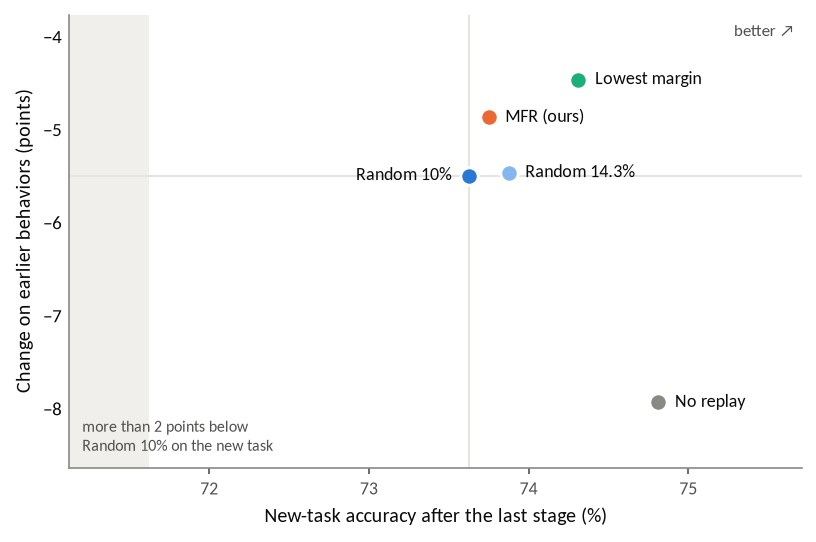

In [9]:
fig, ax = plt.subplots(figsize=(FULL_W * 0.82, 3.5))
xr = means.loc[BASELINE, 'final_task']
xs = {m: means.loc[m, 'final_task'] for m in USED}
ys = {m: means.loc[m, 'old_change'] for m in USED}
x_lo = min(min(xs.values()), xr - TOLERANCE) - 0.5
x_hi = max(xs.values()) + 0.9
y_lo, y_hi = min(ys.values()) - 0.7, max(ys.values()) + 0.7
ax.axvspan(x_lo, xr - TOLERANCE, color=NEUTRAL, zorder=0, lw=0)
ax.text(x_lo + 0.08, y_lo + 0.12, f'more than {TOLERANCE:g} points below\nRandom 10% on the new task',
        fontsize=7.5, color=INK2, va='bottom')
ax.axhline(ys[BASELINE], color=GRID, lw=1, zorder=1)
ax.axvline(xr, color=GRID, lw=1, zorder=1)
for m in USED:
    ax.scatter(xs[m], ys[m], s=70, color=MCOLOR[m], edgecolor='white', linewidth=1.4, zorder=4)
ax.set_xlim(x_lo, x_hi)
ax.set_ylim(y_lo, y_hi)
ax.text(0.99, 0.98, 'better ↗', transform=ax.transAxes, ha='right', va='top', fontsize=8, color=INK2)

# Label placement: try positions around each point; keep the first that overlaps nothing.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
taken = []
for m in USED:
    px, py = ax.transData.transform((xs[m], ys[m]))
    taken.append(matplotlib.transforms.Bbox.from_extents(px - 6, py - 6, px + 6, py + 6))
axes_box = ax.get_window_extent(renderer)
candidates = [(8, 0, 'left', 'center'), (-8, 0, 'right', 'center'), (6, 7, 'left', 'bottom'), (6, -7, 'left', 'top'),
              (-6, 7, 'right', 'bottom'), (-6, -7, 'right', 'top'), (0, 9, 'center', 'bottom'), (0, -9, 'center', 'top')]
candidates += [(dx, dy, ha, 'center') for dy in (14, -14, 24, -24, 34, -34) for dx, ha in ((18, 'left'), (-18, 'right'))]
for m in sorted(USED, key=lambda k: -ys[k]):
    for dx, dy, ha, va in candidates:
        far = abs(dy) > 10
        t = ax.annotate(MLABEL[m], (xs[m], ys[m]), xytext=(dx, dy), textcoords='offset points', ha=ha, va=va,
                        fontsize=8.5, zorder=5,
                        arrowprops=dict(arrowstyle='-', color='#b5b4ae', lw=0.6, shrinkA=0, shrinkB=4) if far else None)
        box = t.get_window_extent(renderer).expanded(1.04, 1.2)
        inside = axes_box.contains(box.x0, box.y0) and axes_box.contains(box.x1, box.y1)
        if inside and not any(box.overlaps(b) for b in taken):
            taken.append(box)
            break
        t.remove()
    else:
        taken.append(ax.annotate(MLABEL[m], (xs[m], ys[m]), xytext=(8, 0), textcoords='offset points',
                                 va='center', fontsize=8.5).get_window_extent(renderer))
ax.set_xlabel('New-task accuracy after the last stage (%)')
ax.set_ylabel('Change on earlier behaviors (points)')
clean_axis(ax, None)
show_fig(fig, 'F2_retention_vs_new_learning',
         'Retention vs new learning (means over 8 cells). Up = less forgetting; right = better learning of the last '
         'behavior. Thin lines mark Random 10%; the shaded band would fail our 2-point new-learning rule.')

## 5. Statistics: every method vs Random 10%, MFR, and Lowest margin (Report §4.3, Table 2)

Paired by cell: each difference is method minus comparison in the **same** order and seed.
Positive = the method is better for all three metrics. "Excludes 0" means the 95% interval does not
contain zero.

In [10]:
stat_rows = []
for c_i, comp in enumerate([BASELINE, 'mfr', 'lowest_margin']):
    if comp not in USED:
        continue
    for m_i, m in enumerate(USED):
        if m == comp:
            continue
        for k_i, (metric, label) in enumerate([('old_change', 'Retention'), ('final_task', 'Final task'),
                                               ('final_average', 'Final average')]):
            r = paired(metric, m, comp, BOOT_SEED + 1000 * c_i + 10 * m_i + k_i)
            stat_rows.append({'Method': MLABEL[m], 'vs': MLABEL[comp], 'Metric': label, 'Difference': r['diff'],
                              '95% low': r['lo'], '95% high': r['hi'],
                              'Excludes 0': 'yes' if r['lo'] > 0 or r['hi'] < 0 else 'no',
                              'Better / tied / worse cells': f"{r['better']} / {r['tied']} / {r['worse']}"})
stats = pd.DataFrame(stat_rows)
show(stats[stats['vs'] == MLABEL[BASELINE]], 'T2a_paired_vs_random', 'Table 2a. Paired differences vs Random 10%')
show(stats[stats['vs'] != MLABEL[BASELINE]], 'T2b_paired_vs_mfr_and_lowest_margin',
     'Table 2b. Paired differences vs MFR and vs Lowest margin')

Method,vs,Metric,Difference,95% low,95% high,Excludes 0,Better / tied / worse cells
No replay,Random 10%,Retention,-2.44,-3.47,-1.44,yes,0 / 0 / 8
No replay,Random 10%,Final task,1.19,0.19,2.19,yes,6 / 0 / 2
No replay,Random 10%,Final average,-0.94,-1.71,-0.19,yes,1 / 0 / 7
Random 14.3%,Random 10%,Retention,0.03,-0.53,0.50,no,4 / 2 / 2
Random 14.3%,Random 10%,Final task,0.25,-0.31,1.00,no,3 / 3 / 2
Random 14.3%,Random 10%,Final average,0.02,-0.31,0.48,no,2 / 2 / 4
MFR (ours),Random 10%,Retention,0.62,0.22,1.09,yes,7 / 0 / 1
MFR (ours),Random 10%,Final task,0.12,-0.31,0.62,no,3 / 3 / 2
MFR (ours),Random 10%,Final average,0.27,-0.06,0.60,no,5 / 1 / 2
Lowest margin,Random 10%,Retention,1.03,0.44,1.50,yes,7 / 0 / 1


Method,vs,Metric,Difference,95% low,95% high,Excludes 0,Better / tied / worse cells
No replay,MFR (ours),Retention,-3.06,-4.00,-2.06,yes,0 / 0 / 8
No replay,MFR (ours),Final task,1.06,0.00,2.25,no,5 / 0 / 3
No replay,MFR (ours),Final average,-1.21,-1.98,-0.46,yes,1 / 0 / 7
Random 10%,MFR (ours),Retention,-0.62,-1.12,-0.22,yes,1 / 0 / 7
Random 10%,MFR (ours),Final task,-0.12,-0.62,0.31,no,2 / 3 / 3
Random 10%,MFR (ours),Final average,-0.27,-0.60,0.06,no,2 / 1 / 5
Random 14.3%,MFR (ours),Retention,-0.59,-1.06,-0.19,yes,1 / 1 / 6
Random 14.3%,MFR (ours),Final task,0.12,-0.56,0.88,no,3 / 1 / 4
Random 14.3%,MFR (ours),Final average,-0.25,-0.44,-0.04,yes,1 / 1 / 6
Lowest margin,MFR (ours),Retention,0.41,-0.34,1.12,no,6 / 0 / 2


### Figure 3: paired differences from Random 10%

Points right of zero are better than equal-budget random replay. Left panel: retention. Right panel:
final three-behavior average.

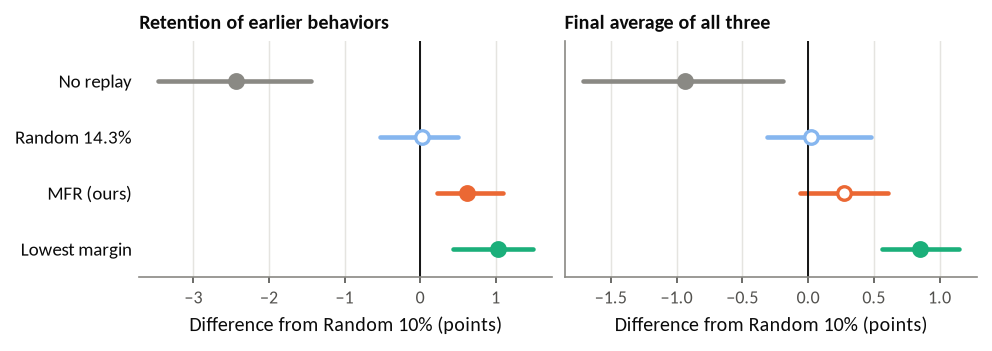

In [11]:
vs = stats[stats['vs'] == MLABEL[BASELINE]]
methods_vs = [m for m in order_methods if m != BASELINE]
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 0.32 * len(methods_vs) + 0.95), sharey=True)
for ax, metric, title in zip(axes, ['Retention', 'Final average'],
                             ['Retention of earlier behaviors', 'Final average of all three']):
    part = vs[vs['Metric'] == metric].set_index('Method')
    for y, m in enumerate(methods_vs):
        r = part.loc[MLABEL[m]]
        sure = r['95% low'] > 0 or r['95% high'] < 0
        ax.plot([r['95% low'], r['95% high']], [y, y], color=MCOLOR[m], lw=2.2, solid_capstyle='round', zorder=2)
        ax.scatter(r['Difference'], y, s=42, zorder=3, color=MCOLOR[m] if sure else 'white',
                   edgecolor=MCOLOR[m], linewidth=1.6)
    ax.axvline(0, color=INK, lw=0.9)
    ax.set_title(title)
    ax.set_xlabel('Difference from Random 10% (points)')
    clean_axis(ax, 'x')
method_axis(axes[0], methods_vs)
show_fig(fig, 'F3_paired_vs_random',
         'Paired difference from Random 10% (same order and seed), with 95% bootstrap intervals over 8 cells. '
         'Right of zero is better. Filled dot: the interval excludes zero.')

## 6. Forgetting per behavior (Report §4.3, Table 3)

Helpful and Safe are earlier behaviors in 6 of 8 cells; Quality in 4 (it is learned first only in
orders 3–4 and is never in the middle; state this as a limitation).

dataset,Method,Helpful (n=6),Safe (n=6),Quality (n=4),Worst behavior
,No replay,-6.25,-13.25,-2.50,-13.25
,Random 10%,-4.50,-8.75,-2.12,-8.75
,Random 14.3%,-5.00,-8.08,-2.25,-8.08
,MFR (ours),-4.83,-7.33,-1.25,-7.33
,Lowest margin,-4.42,-6.67,-1.25,-6.67


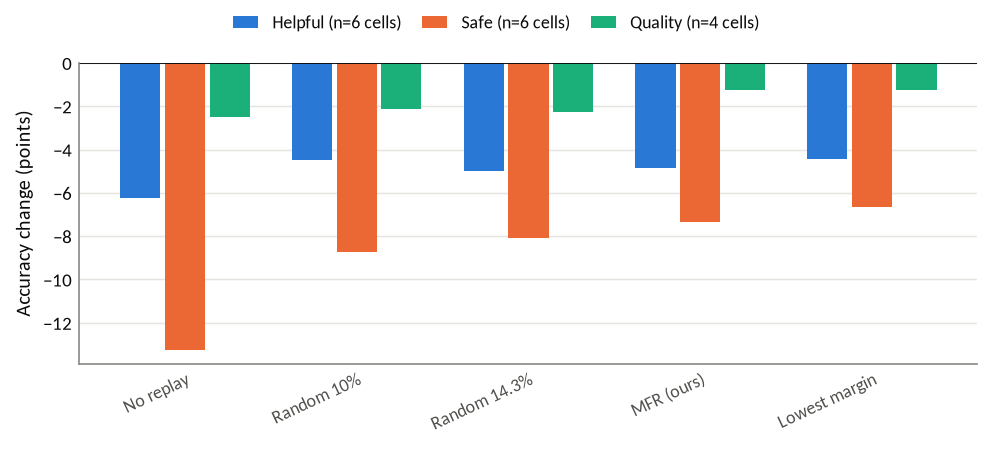

In [12]:
pb = per_behavior.groupby(['method', 'dataset'])['change'].agg(['mean', 'count']).reset_index()
t3 = pb.pivot(index='method', columns='dataset', values='mean').reindex(order_methods).reindex(columns=DATASETS)
counts = pb.pivot(index='method', columns='dataset', values='count').max()
t3_out = t3.reset_index().rename(columns={'method': 'Method', **{d: f'{DLABEL[d]} (n={int(counts[d])})' for d in DATASETS}})
t3_out['Method'] = t3_out['Method'].map(MLABEL)
t3_out['Worst behavior'] = t3.min(axis=1).to_numpy()
show(t3_out, 'T3_forgetting_by_behavior', 'Table 3. Old-behavior change by behavior (mean over cells where it is an earlier behavior)')

fig, ax = plt.subplots(figsize=(FULL_W, 2.9))
x = np.arange(len(order_methods)); w = 0.26
for i, d in enumerate(DATASETS):
    ax.bar(x + (i - 1) * w, t3[d].to_numpy(), w * 0.9, color=DCOLOR[d], label=f'{DLABEL[d]} (n={int(counts[d])} cells)', zorder=2)
ax.axhline(0, color=INK, lw=0.9)
ax.set_xticks(x, [MLABEL[m] for m in order_methods], rotation=25, ha='right', rotation_mode='anchor')
ax.tick_params(axis='x', length=0)
ax.set_ylabel('Accuracy change (points)')
fig.legend(loc='outside upper center', ncol=3)
clean_axis(ax, 'y')
show_fig(fig, 'F4_forgetting_by_behavior',
         'Forgetting by behavior: accuracy change from right after the behavior was learned to the end of training, '
         'averaged over the cells where it is an earlier behavior. Closer to 0 is better.')

### Final accuracy per behavior and the gap to joint training (Report §4.3)

In [13]:
fin = per_run.groupby('method')[[f'final_{d}' for d in DATASETS] + ['final_average']].mean().reindex(order_methods)
fin_out = fin.reset_index().rename(columns={'method': 'Method', **{f'final_{d}': DLABEL[d] for d in DATASETS},
                                            'final_average': 'Average'})
fin_out['Method'] = fin_out['Method'].map(MLABEL)
if np.isfinite(JOINT_AVG):
    fin_out = pd.concat([fin_out, pd.DataFrame([{'Method': 'Joint training (reference)',
                                                 **{DLABEL[d]: JOINT_BY_D[d] for d in DATASETS}, 'Average': JOINT_AVG}])],
                        ignore_index=True)
show(fin_out, 'T4_final_accuracy_by_behavior', 'Table 4. Final accuracy per behavior after all three stages')

Method,Helpful,Safe,Quality,Average
No replay,64.94,74.62,72.75,70.77
Random 10%,65.56,76.81,72.75,71.71
Random 14.3%,65.44,77.12,72.62,71.73
MFR (ours),65.25,77.31,73.38,71.98
Lowest margin,65.62,78.44,73.62,72.56
Joint training (reference),67.25,82.00,72.75,74.00


## 7. Does a method protect what was learned, or fix what was weak? (Report §3.6, §4.3)

For each earlier behavior we compare every validation pair **right after it was learned** with the
**end of training**. A pair is correct when its margin is above 0 (the model prefers the chosen answer
more than the base model does).

| | Correct at end | Incorrect at end |
|---|---|---|
| **Correct when learned** | Kept | **Forgotten** |
| **Incorrect when learned** | **Recovered** | Never learned |

- **Forgotten share** and **recovered share** are percentages of all 200 pairs, so
  `net change = recovered share − forgotten share` (this equals the old-behavior change).
- **Forgetting rate** = forgotten / pairs correct when learned. **Recovery rate** = recovered / pairs
  incorrect when learned. Their denominators differ, so they do not add up.

Validation pairs are never replayed (the buffer comes from the training split), so this measures
whether protection **generalizes**.

In [14]:
trans_rows, pair_frames = [], []
for (method, order_id, seed), rec in records.items():
    order, last = rec['order'], len(rec['order'])
    for learned_at, d in enumerate(order[:-1], 1):
        a = margins(rec, learned_at, d)[['id', MARGIN_COL]].rename(columns={MARGIN_COL: 'learned'})
        z = margins(rec, last, d)[['id', MARGIN_COL]].rename(columns={MARGIN_COL: 'final'})
        q = a.merge(z, on='id')
        cl, cf = q['learned'] > 0, q['final'] > 0
        n = len(q)
        kept, forgotten = int((cl & cf).sum()), int((cl & ~cf).sum())
        recovered, never = int((~cl & cf).sum()), int((~cl & ~cf).sum())
        trans_rows.append({'method': method, 'order_id': order_id, 'seed': seed, 'dataset': d, 'n': n,
                           'kept': kept, 'forgotten': forgotten, 'recovered': recovered, 'never': never,
                           'forgotten_share': 100 * forgotten / n, 'recovered_share': 100 * recovered / n,
                           'net_change': 100 * (recovered - forgotten) / n,
                           'forgetting_rate': 100 * forgotten / max(kept + forgotten, 1),
                           'recovery_rate': 100 * recovered / max(recovered + never, 1),
                           'margin_change_known': float((q['final'] - q['learned'])[cl].mean())})
        q = q.assign(method=method, order_id=order_id, seed=seed, dataset=d)
        pair_frames.append(q)
transitions = pd.DataFrame(trans_rows)
pairs = pd.concat(pair_frames, ignore_index=True)

check = transitions.merge(per_behavior, on=['method', 'order_id', 'seed', 'dataset'])
mismatch = check[(check['net_change'] - check['change']).abs() > 0.051]
print('Margin-level accuracy matches results.csv for every run and behavior.' if mismatch.empty
      else f'WARNING: {len(mismatch)} run-behavior rows disagree with results.csv')

per_run_t = transitions.groupby(['method', 'order_id', 'seed'])[
    ['forgotten_share', 'recovered_share', 'net_change', 'forgetting_rate', 'recovery_rate', 'margin_change_known']].mean().reset_index()
t5 = per_run_t.groupby('method')[['forgotten_share', 'recovered_share', 'net_change', 'forgetting_rate',
                                  'recovery_rate', 'margin_change_known']].mean().reindex(order_methods)
rows = []
for i, m in enumerate(order_methods):
    f = paired('forgotten_share', m, BASELINE, BOOT_SEED + 300 + i, per_run_t) if m != BASELINE else None
    r = paired('recovered_share', m, BASELINE, BOOT_SEED + 400 + i, per_run_t) if m != BASELINE else None
    rows.append({'Method': MLABEL[m], 'Forgotten (% of pairs)': t5.loc[m, 'forgotten_share'],
                 'Recovered (% of pairs)': t5.loc[m, 'recovered_share'], 'Net change': t5.loc[m, 'net_change'],
                 'Forgetting rate (% of known)': t5.loc[m, 'forgetting_rate'],
                 'Recovery rate (% of unknown)': t5.loc[m, 'recovery_rate'],
                 'Δ forgotten vs Random [95%]': f"{f['diff']:+.2f} [{f['lo']:+.2f}, {f['hi']:+.2f}]" if f else '—',
                 'Δ recovered vs Random [95%]': f"{r['diff']:+.2f} [{r['lo']:+.2f}, {r['hi']:+.2f}]" if r else '—',
                 'Mean margin change of known pairs': t5.loc[m, 'margin_change_known']})
table5 = pd.DataFrame(rows)
show(table5, 'T5_transitions', 'Table 5. Where the net change comes from (mean over 8 cells × 2 earlier behaviors)', decimals=3)

Margin-level accuracy matches results.csv for every run and behavior.


Method,Forgotten (% of pairs),Recovered (% of pairs),Net change,Forgetting rate (% of known),Recovery rate (% of unknown),Δ forgotten vs Random [95%],Δ recovered vs Random [95%],Mean margin change of known pairs
No replay,13.094,5.156,-7.938,16.988,21.299,"+2.94 [+2.09, +3.78]","+0.50 [+0.03, +1.00]",-0.010
Random 10%,10.156,4.656,-5.500,13.362,18.615,—,—,-0.004
Random 14.3%,9.969,4.500,-5.469,13.196,17.759,"-0.19 [-0.50, +0.22]","-0.16 [-0.38, +0.03]",-0.002
MFR (ours),9.062,4.188,-4.875,11.995,16.674,"-1.09 [-1.50, -0.72]","-0.47 [-0.88, -0.09]",-0.002
Lowest margin,9.156,4.688,-4.469,12.112,18.957,"-1.00 [-1.38, -0.59]","+0.03 [-0.31, +0.41]",-0.003


### Figure 5: forgotten vs recovered pairs

Left of zero: pairs that were correct when learned and wrong at the end. Right of zero: pairs that
were wrong when learned and correct at the end. The black dot is the net change.

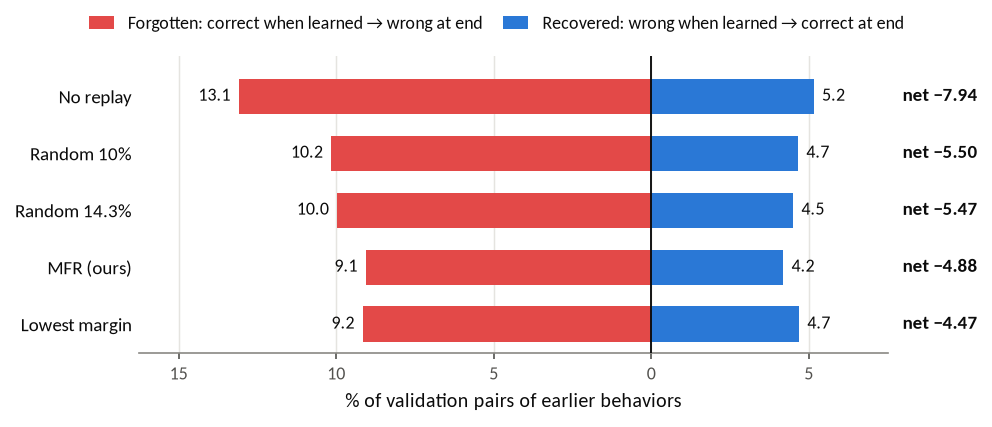

In [15]:
fig, ax = plt.subplots(figsize=(FULL_W, 0.36 * len(order_methods) + 0.95))
for y, m in enumerate(order_methods):
    f, r, n = t5.loc[m, 'forgotten_share'], t5.loc[m, 'recovered_share'], t5.loc[m, 'net_change']
    ax.barh(y, -f, height=0.62, color=FORGET_C, zorder=2, label='Forgotten: correct when learned → wrong at end' if y == 0 else None)
    ax.barh(y, r, height=0.62, color=RECOVER_C, zorder=2, label='Recovered: wrong when learned → correct at end' if y == 0 else None)
    ax.annotate(num(f, 1), (-f, y), xytext=(-4, 0), textcoords='offset points', va='center', ha='right', fontsize=8.5)
    ax.annotate(num(r, 1), (r, y), xytext=(4, 0), textcoords='offset points', va='center', ha='left', fontsize=8.5)
    ax.text(1.02, y, f'net {num(n, 2)}', transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=9,
            fontweight='bold')
ax.axvline(0, color=INK, lw=0.9, zorder=3)
method_axis(ax, order_methods)
ax.set_xlim(-(t5['forgotten_share'].max() * 1.18 + 0.8), t5['recovered_share'].max() * 1.3 + 0.8)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{abs(v):g}'))
ax.set_xlabel('% of validation pairs of earlier behaviors')
fig.legend(loc='outside upper center', ncol=2)
clean_axis(ax, 'x')
show_fig(fig, 'F5_forgotten_vs_recovered',
         'Where the net change comes from. Left: pairs correct right after learning but wrong at the end. Right: pairs '
         'wrong after learning but correct at the end. Net = recovered − forgotten (= old-behavior change).')

### Figure 6: the full 2×2 transition table per method (appendix)

Each matrix is the **mean over all 8 runs** (4 orders × 2 seeds) of the percent of earlier-behavior validation pairs
in each box. Pooling the counts gives exactly the same numbers, because every run contributes the same number of
pairs (2 earlier behaviors × 200).

Read it with care: the orders behave very differently (section 12b), so this average mixes runs that forget a lot
(orders 1–2) with runs that forget little (orders 3–4). The per-order version is Figure 14. Only the two off-diagonal
boxes (forgotten, recovered) depend much on the method; the diagonal mostly shows how well a behavior was learned.

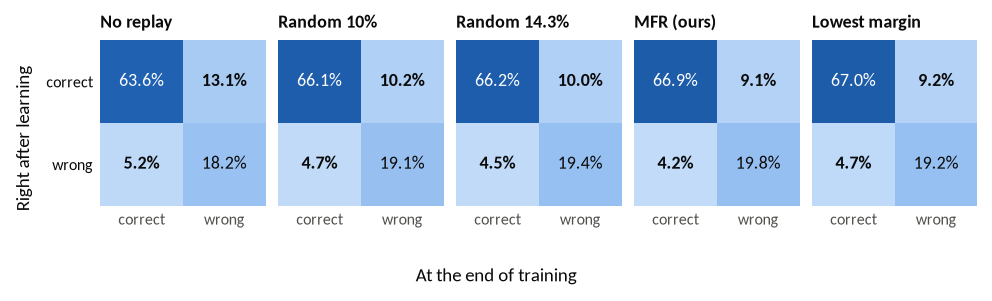

In [16]:
pool = transitions.groupby('method')[['kept', 'forgotten', 'recovered', 'never', 'n']].sum().reindex(order_methods)
ncol = min(5, len(order_methods)); nrow = math.ceil(len(order_methods) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(FULL_W, 1.55 * nrow + 0.5), squeeze=False)
axes = axes.ravel()
for idx, (ax, m) in enumerate(zip(axes, order_methods)):
    p = pool.loc[m]
    mat = 100 * np.array([[p['kept'], p['forgotten']], [p['recovered'], p['never']]]) / p['n']
    ax.imshow(mat, cmap=SEQUENTIAL, vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{mat[i, j]:.1f}%', ha='center', va='center', fontsize=8.5,
                    color='white' if mat[i, j] > 45 else INK, fontweight='bold' if (i + j) == 1 else 'normal')
    ax.set_xticks([0, 1], ['correct', 'wrong'], fontsize=7.5)
    ax.set_yticks([0, 1], ['correct', 'wrong'] if idx % ncol == 0 else ['', ''], fontsize=7.5)
    ax.set_title(MLABEL[m], fontsize=8.5)
    no_frame(ax)
for ax in axes[len(order_methods):]:
    ax.axis('off')
fig.supxlabel('At the end of training', fontsize=9)
fig.supylabel('Right after learning', fontsize=9)
show_fig(fig, 'F6_transition_matrices',
         'Transition of each validation pair of an earlier behavior from right after learning (rows) to the end of '
         'training (columns), as % of pairs, mean over all 8 order–seed runs. Bold: forgotten (top right) and recovered (bottom left).')

## 8. Are weakly learned pairs forgotten differently? (Report §4.3, discussion)

MFR ranks pairs by how far their margin **dropped**. A pair that was learned only weakly cannot drop
far, so MFR rarely picks it, even if it is about to flip. Lowest margin picks exactly those pairs.
To test this, the pairs that were correct when learned are split into quartiles of their learned
margin within each run and behavior (Q1 = weakest correct pairs, Q4 = strongest). For each quartile we
report the **forgetting rate** and the **mean margin drop**.

Method,Q1 forgetting rate (%),Q2 forgetting rate (%),Q3 forgetting rate (%),Q4 forgetting rate (%),Q1 margin drop,Q2 margin drop,Q3 margin drop,Q4 margin drop
No replay,35.467,16.963,9.864,5.545,0.005,0.009,0.011,0.014
Random 10%,30.758,13.407,7.002,2.194,0.003,0.007,0.005,0.001
Random 14.3%,31.278,12.664,6.700,2.046,0.003,0.006,0.004,-0.005
MFR (ours),29.706,11.005,5.328,1.781,0.003,0.006,0.004,-0.004
Lowest margin,28.015,12.072,5.474,2.737,0.002,0.004,0.002,0.004


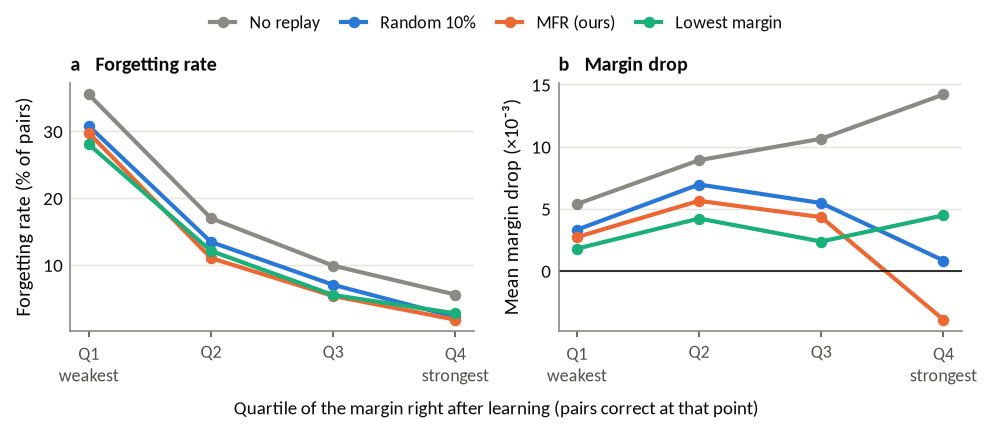

In [17]:
known = pairs[pairs['learned'] > 0].copy()
known['quartile'] = (known.groupby(['method', 'order_id', 'seed', 'dataset'])['learned']
                     .transform(lambda s: pd.qcut(s.rank(method='first'), 4, labels=False) + 1))
known['forgot'] = (known['final'] <= 0).astype(float)
known['drop'] = known['learned'] - known['final']
quart = (known.groupby(['method', 'order_id', 'seed', 'dataset', 'quartile'])
         .agg(rate=('forgot', 'mean'), drop=('drop', 'mean'), learned=('learned', 'mean')).reset_index()
         .groupby(['method', 'quartile'])[['rate', 'drop', 'learned']].mean().reset_index())
quart['rate'] *= 100
q_rate = quart.pivot(index='method', columns='quartile', values='rate').reindex(order_methods)
q_drop = quart.pivot(index='method', columns='quartile', values='drop').reindex(order_methods)
t6 = pd.DataFrame({'Method': [MLABEL[m] for m in order_methods]})
for qq in [1, 2, 3, 4]:
    t6[f'Q{qq} forgetting rate (%)'] = q_rate[qq].to_numpy()
for qq in [1, 2, 3, 4]:
    t6[f'Q{qq} margin drop'] = q_drop[qq].to_numpy()
show(t6, 'T6_forgetting_by_learned_margin', 'Table 6. Forgetting by learned-margin quartile (Q1 = weakest correct pairs)', decimals=3)

key = [m for m in KEY_METHODS if m in USED]
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.8))
for m in key:
    axes[0].plot([1, 2, 3, 4], q_rate.loc[m, [1, 2, 3, 4]], marker='o', ms=4.5, color=MCOLOR[m], label=MLABEL[m])
    axes[1].plot([1, 2, 3, 4], 1000 * q_drop.loc[m, [1, 2, 3, 4]], marker='o', ms=4.5, color=MCOLOR[m])
axes[0].set_ylabel('Forgetting rate (% of pairs)')
axes[1].set_ylabel('Mean margin drop (×10⁻³)')
axes[1].axhline(0, color=INK, lw=0.8)
for ax, title in zip(axes, ['a   Forgetting rate', 'b   Margin drop']):
    ax.set_xticks([1, 2, 3, 4], ['Q1\nweakest', 'Q2', 'Q3', 'Q4\nstrongest'])
    ax.set_title(title)
    clean_axis(ax, 'y')
fig.supxlabel('Quartile of the margin right after learning (pairs correct at that point)', fontsize=9)
fig.legend(loc='outside upper center', ncol=len(key))
show_fig(fig, 'F7_forgetting_by_learned_margin',
         'Pairs that were correct right after learning, split into quartiles of their learned margin (Q1 = barely '
         'correct). (a) Share that is wrong at the end. (b) Mean drop in margin by the end.')

## 9. How an early behavior fades across stages (Report §4.2 / §4.3)

For each order, the accuracy of the **first** behavior after stages 1, 2, and 3 (mean over 2 seeds).
Stage 1 is identical for every method.

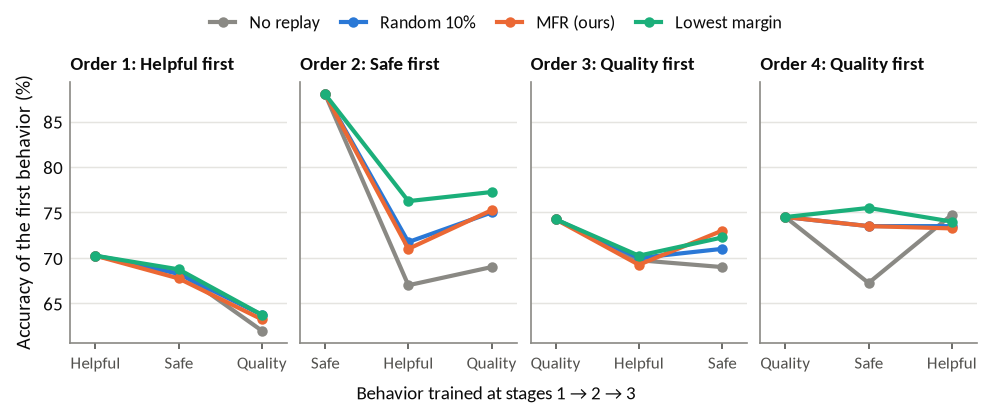

Example (order 1, seed 0, No replay): Safety 83.5% right after learning → 74.5% at the end (-9.0 points).
   after stage 2 (Safe): Safety = 83.5%
   after stage 3 (Quality): Safety = 74.5%


In [18]:
curve_rows = []
for (method, order_id, seed), rec in records.items():
    first = rec['order'][0]
    for stage in [1, 2, 3]:
        curve_rows.append({'method': method, 'order_id': order_id, 'seed': seed, 'stage': stage,
                           'accuracy': acc(results[(method, order_id, seed)], stage, first)})
curves = pd.DataFrame(curve_rows).groupby(['order_id', 'method', 'stage'])['accuracy'].mean().reset_index()
fig, axes = plt.subplots(1, len(ORDERS), figsize=(FULL_W, 2.7), sharey=True, squeeze=False)
axes = axes.ravel()
for ax, o in zip(axes, ORDERS):
    order = PROTOCOL_ORDERS.get(o) or next(r['order'] for r in records.values() if r['order_id'] == o)
    for m in key:
        p = curves[(curves['order_id'] == o) & (curves['method'] == m)].sort_values('stage')
        ax.plot(p['stage'], p['accuracy'], marker='o', ms=4, color=MCOLOR[m], label=MLABEL[m])
    ax.set_xticks([1, 2, 3], [DLABEL[d] for d in order], fontsize=8)
    ax.set_xlim(0.7, 3.3)
    ax.set_title(f'Order {o}: {DLABEL[order[0]]} first', fontsize=9)
    clean_axis(ax, 'y')
axes[0].set_ylabel('Accuracy of the first behavior (%)')
fig.supxlabel('Behavior trained at stages 1 → 2 → 3', fontsize=9)
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside upper center', ncol=len(key))
show_fig(fig, 'F8_first_behavior_across_stages',
         'Accuracy of the first-learned behavior after each stage, per training order (mean of 2 seeds). Stage 1 is '
         'shared by all methods; later drops are forgetting.')

ex_o, ex_s = EXAMPLE_CELL
ex = results.get(('none', ex_o, ex_s))
if ex is not None:
    ex_order = records[('none', ex_o, ex_s)]['order']
    if 'safe' in ex_order[:-1]:
        k = ex_order.index('safe') + 1
        print(f"Example (order {ex_o}, seed {ex_s}, No replay): Safety {acc(ex, k, 'safe'):.1f}% right after learning "
              f"→ {acc(ex, len(ex_order), 'safe'):.1f}% at the end "
              f"({acc(ex, len(ex_order), 'safe') - acc(ex, k, 'safe'):+.1f} points).")
        for stage in range(k, len(ex_order) + 1):
            print(f'   after stage {stage} ({DLABEL[ex_order[stage - 1]]}): Safety = {acc(ex, stage, "safe"):.1f}%')

## 10. What did each method replay? (mechanism; Report §4.3 discussion and §5.1)

From the replay logs of stages 2–3. All methods store the **same** buffer pairs in a cell, so
overlap between methods is meaningful.

- **Unique pairs** and **uses per pair**: how spread out the replay was.
- **Top-10% share**: share of replay slots taken by the 10% most-replayed pairs (concentration).
- **Slots per source behavior**: whether a method spends its budget mostly on one behavior.

Method,Replay slots per stage,Unique pairs per stage,Uses per pair,Top-10% pairs share of slots (%)
Random 10%,222.0,185.50,1.20,19.03
Random 14.3%,333.0,256.25,1.30,19.29
MFR (ours),222.0,126.94,1.83,22.47
Lowest margin,222.0,117.00,2.06,23.79


Method,Stage-3 slots spent on Safe (%),Equal split would be (%)
Random 10%,49.25,50.0
Random 14.3%,49.45,50.0
MFR (ours),69.89,50.0
Lowest margin,53.68,50.0


Method,Random 10%,Random 14.3%,MFR (ours),Lowest margin
Random 10%,1.00,0.72,0.25,0.16
Random 14.3%,0.72,1.00,0.25,0.19
MFR (ours),0.25,0.25,1.00,0.21
Lowest margin,0.16,0.19,0.21,1.00


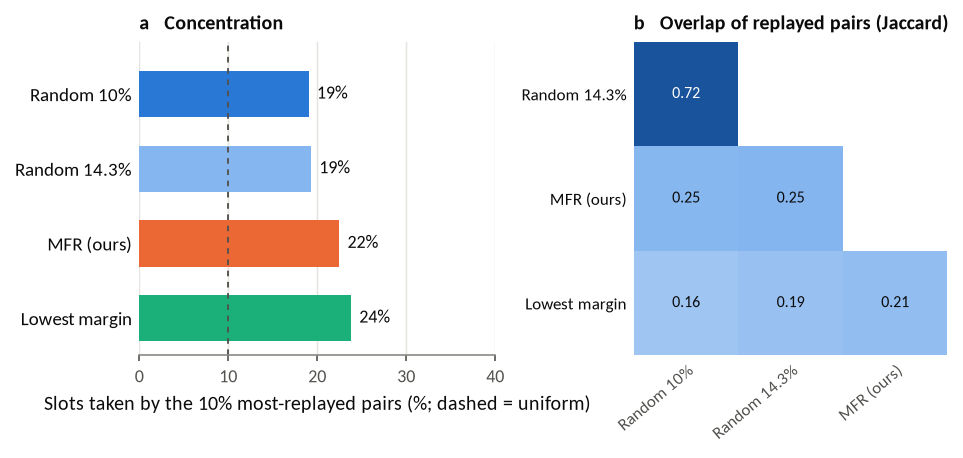

In [19]:
log_rows, id_sets = [], {}
for (method, order_id, seed), rec in records.items():
    if method == 'none':
        continue
    for stage in range(2, len(rec['order']) + 1):
        path = stage_dir(rec, stage) / 'replay_log.csv'
        if not path.exists():
            continue
        log = pd.read_csv(path)
        if log.empty:
            continue
        counts_id = log['id'].value_counts()
        top = int(math.ceil(0.10 * len(counts_id)))
        src = log['dataset'].value_counts(normalize=True)
        log_rows.append({'method': method, 'order_id': order_id, 'seed': seed, 'stage': stage, 'slots': len(log),
                         'unique': len(counts_id), 'uses_per_pair': len(log) / len(counts_id),
                         'top10_share': 100 * counts_id.iloc[:top].sum() / len(log),
                         **{f'share_{d}': 100 * float(src.get(d, 0.0)) for d in DATASETS}})
        id_sets[(method, order_id, seed, stage)] = set(log['id'])
replay = pd.DataFrame(log_rows)
if len(replay):
    rep_methods = [m for m in order_methods if m in set(replay['method'])]
    t7 = replay.groupby('method')[['slots', 'unique', 'uses_per_pair', 'top10_share']].mean().reindex(rep_methods)
    t7_out = t7.reset_index().rename(columns={'method': 'Method', 'slots': 'Replay slots per stage',
                                              'unique': 'Unique pairs per stage', 'uses_per_pair': 'Uses per pair',
                                              'top10_share': 'Top-10% pairs share of slots (%)'})
    t7_out['Method'] = t7_out['Method'].map(MLABEL)
    show(t7_out, 'T7_replay_concentration', 'Table 7. How concentrated replay was (stages 2–3, mean over runs)')

    # Allocation across source behaviors in stage 3 (two old behaviors available), per order.
    alloc = replay[replay['stage'] == 3].copy()
    alloc_rows = []
    for (m, o), g in alloc.groupby(['method', 'order_id']):
        old = (PROTOCOL_ORDERS.get(o) or next(r['order'] for r in records.values() if r['order_id'] == o))[:2]
        alloc_rows.append({'method': m, 'order_id': o, 'first': old[0], 'second': old[1],
                           'share_first': g[f'share_{old[0]}'].mean(), 'share_second': g[f'share_{old[1]}'].mean()})
    alloc = pd.DataFrame(alloc_rows)
    safe_share = []
    for m in rep_methods:
        g = alloc[alloc['method'] == m]
        s = [r['share_first'] if r['first'] == 'safe' else r['share_second'] for _, r in g.iterrows() if 'safe' in (r['first'], r['second'])]
        safe_share.append(np.mean(s) if s else np.nan)
    t7b = pd.DataFrame({'Method': [MLABEL[m] for m in rep_methods], 'Stage-3 slots spent on Safe (%)': safe_share,
                        'Equal split would be (%)': 50.0})
    show(t7b, 'T7b_safe_share', 'Table 7b. Share of stage-3 replay spent on Safe, when Safe is an old behavior')

    # Jaccard overlap of the pairs chosen by each method (same cell and stage).
    jac = pd.DataFrame(np.nan, index=rep_methods, columns=rep_methods)
    for a in rep_methods:
        for b in rep_methods:
            vals = [len(id_sets[(a, o, s, st)] & id_sets[(b, o, s, st)]) / len(id_sets[(a, o, s, st)] | id_sets[(b, o, s, st)])
                    for (mm, o, s, st) in id_sets if mm == a and (b, o, s, st) in id_sets]
            jac.loc[a, b] = np.mean(vals) if vals else np.nan
    jac_out = jac.copy(); jac_out.index = [MLABEL[m] for m in jac.index]; jac_out.columns = [MLABEL[m] for m in jac.columns]
    show(jac_out.reset_index().rename(columns={'index': 'Method'}), 'T8_selection_overlap',
         'Table 8. Overlap (Jaccard) of the replayed pairs, same cell and stage')

    fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 0.36 * len(rep_methods) + 1.5), width_ratios=[1, 1.05])
    ax = axes[0]
    for y, m in enumerate(rep_methods):
        v = t7.loc[m, 'top10_share']
        ax.barh(y, v, height=0.62, color=MCOLOR[m], zorder=2)
        ax.annotate(f"{v:.0f}%", (v, y), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8.5)
    ax.axvline(10, color=INK2, lw=0.9, ls=(0, (3, 3)))
    method_axis(ax, rep_methods)
    ax.set_xlim(0, max(40, t7['top10_share'].max() * 1.25))
    ax.set_xlabel('Slots taken by the 10% most-replayed pairs (%; dashed = uniform)')
    ax.set_title('a   Concentration')
    clean_axis(ax, 'x')
    ax = axes[1]
    mat = jac.to_numpy(dtype=float).copy()
    mat[np.triu_indices_from(mat)] = np.nan          # lower triangle only
    ax.imshow(mat, cmap=SEQUENTIAL, vmin=0, vmax=1)
    for i in range(len(rep_methods)):
        for j in range(i):
            ax.text(j, i, f'{mat[i, j]:.2f}', ha='center', va='center', fontsize=7.5,
                    color='white' if mat[i, j] > 0.55 else INK)
    ax.set_xticks(range(len(rep_methods)), [MLABEL[m] for m in rep_methods], rotation=40, ha='right',
                  rotation_mode='anchor', fontsize=8)
    ax.set_yticks(range(len(rep_methods)), [MLABEL[m] for m in rep_methods], fontsize=8)
    ax.set_xlim(-0.5, len(rep_methods) - 1.5)
    ax.set_ylim(len(rep_methods) - 0.5, 0.5)
    ax.set_title('b   Overlap of replayed pairs (Jaccard)')
    no_frame(ax)
    show_fig(fig, 'F9_replay_mechanism',
             '(a) How concentrated replay is: share of replay slots used by the 10% most-replayed pairs (dashed: '
             'uniform). (b) Overlap between the sets of pairs two methods replayed in the same cell and stage.')
else:
    print('No replay logs found.')

## 11. Cost (Report §4.1 / §5)

Minutes per run from the training histories. Stage 1 is shared, so the comparison that matters is
stages 2–3. Scoring minutes are the extra time spent re-scoring the buffer (margin-based methods).

Method,"Minutes, stages 2–3",of which buffer re-scoring,Replayed examples,vs Random 10% (×)
No replay,14.59,0.00,0.0,0.89
Random 10%,16.40,0.00,444.0,1.00
Random 14.3%,17.02,0.00,666.0,1.04
MFR (ours),20.39,4.28,444.0,1.24
Lowest margin,20.70,4.28,444.0,1.26


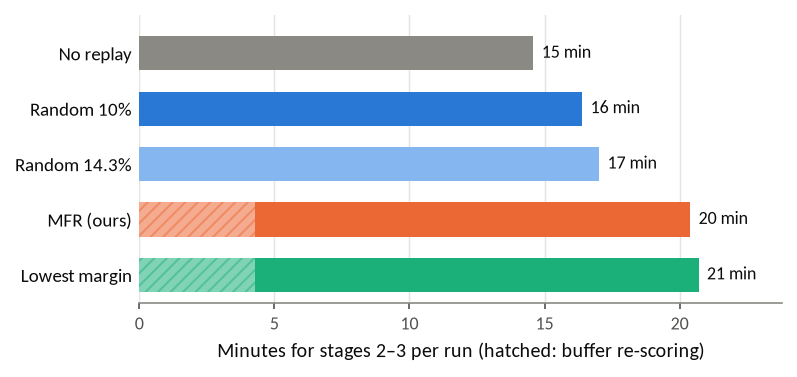

In [20]:
cost_rows = []
for (method, order_id, seed), rec in records.items():
    later = scoring = 0.0; replayed = 0
    for stage in range(2, len(rec['order']) + 1):
        path = stage_dir(rec, stage) / 'history.csv'
        if not path.exists():
            continue
        h = pd.read_csv(path)
        later += float(h['minutes'].max())
        scoring += float(h['scoring_minutes'].max()) if 'scoring_minutes' in h else 0.0
        replayed += int(h['n_replay'].sum()) if 'n_replay' in h else 0
    cost_rows.append({'method': method, 'order_id': order_id, 'seed': seed, 'minutes_stage23': later,
                      'scoring_minutes': scoring, 'replay_examples': replayed})
cost = pd.DataFrame(cost_rows).groupby('method')[['minutes_stage23', 'scoring_minutes', 'replay_examples']].mean().reindex(order_methods)
cost_out = cost.reset_index().rename(columns={'method': 'Method', 'minutes_stage23': 'Minutes, stages 2–3',
                                              'scoring_minutes': 'of which buffer re-scoring',
                                              'replay_examples': 'Replayed examples'})
cost_out['Method'] = cost_out['Method'].map(MLABEL)
cost_out['vs Random 10% (×)'] = (cost['minutes_stage23'] / cost.loc[BASELINE, 'minutes_stage23']).to_numpy()
show(cost_out, 'T9_cost', 'Table 9. Training cost per run (mean over 8 cells; L40S)')

fig, ax = plt.subplots(figsize=(FULL_W * 0.8, 0.32 * len(order_methods) + 0.8))
for y, m in enumerate(order_methods):
    total, scoring = cost.loc[m, 'minutes_stage23'], cost.loc[m, 'scoring_minutes']
    ax.barh(y, total, height=0.62, color=MCOLOR[m], zorder=2)
    if scoring > 0:
        ax.barh(y, scoring, height=0.62, color='white', alpha=0.45, zorder=3, hatch='////', edgecolor=MCOLOR[m], lw=0)
    ax.annotate(f'{total:.0f} min', (total, y), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8.5)
method_axis(ax, order_methods)
ax.set_xlim(0, cost['minutes_stage23'].max() * 1.15)
ax.set_xlabel('Minutes for stages 2–3 per run (hatched: buffer re-scoring)')
clean_axis(ax, 'x')
show_fig(fig, 'F10_runtime',
         'Training time per run for stages 2–3 (stage 1 is shared), mean over 8 cells on one L40S GPU. Hatched: time '
         'spent re-scoring the replay buffer, needed by margin-based methods.')

## 12. Every cell (appendix; shows the result is not driven by one order or seed)

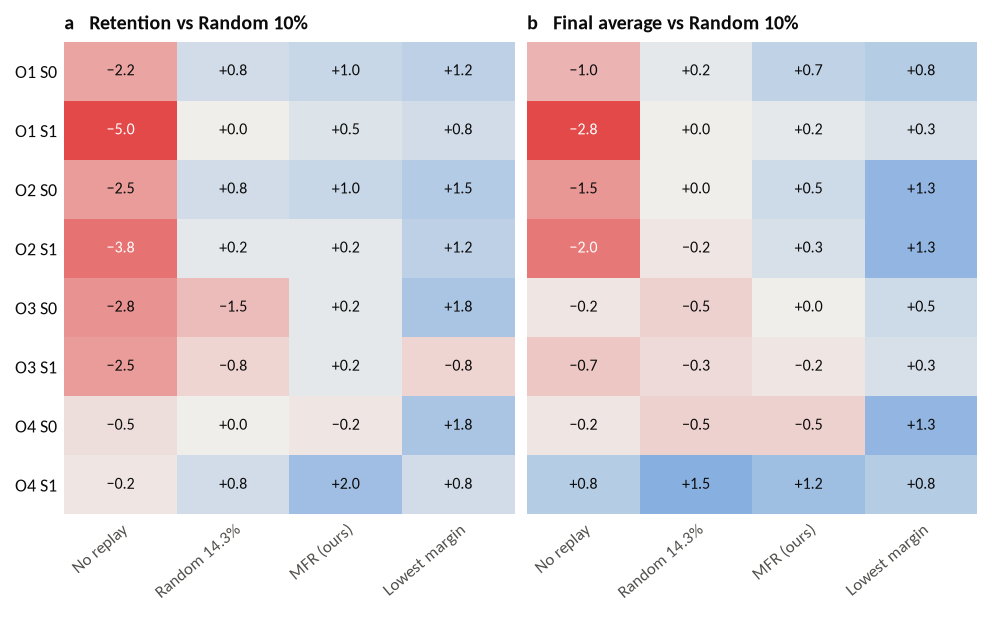

method,Order,Seed,No replay,Random 10%,Random 14.3%,MFR (ours),Lowest margin
,1,0,-9.00,-6.75,-6.00,-5.75,-5.50
,1,1,-10.50,-5.50,-5.50,-5.00,-4.75
,2,0,-12.50,-10.00,-9.25,-9.00,-8.50
,2,1,-13.50,-9.75,-9.50,-9.50,-8.50
,3,0,-4.00,-1.25,-2.75,-1.00,0.50
,3,1,-4.75,-2.25,-3.00,-2.00,-3.00
,4,0,-3.75,-3.25,-3.25,-3.50,-1.50
,4,1,-5.50,-5.25,-4.50,-3.25,-4.50


method,Order,Seed,No replay,Random 10%,Random 14.3%,MFR (ours),Lowest margin
,1,0,70.33,71.33,71.50,72.00,72.17
,1,1,69.50,72.33,72.33,72.50,72.67
,2,0,69.17,70.67,70.67,71.17,72.00
,2,1,67.67,69.67,69.50,70.00,71.00
,3,0,73.17,73.33,72.83,73.33,73.83
,3,1,72.17,72.83,72.50,72.67,73.17
,4,0,72.50,72.67,72.17,72.17,74.00
,4,1,71.67,70.83,72.33,72.00,71.67


method,Order,Seed,No replay,Random 10%,Random 14.3%,MFR (ours),Lowest margin
,1,0,74.5,73.5,74.0,75.0,75.0
,1,1,74.0,75.0,75.0,74.5,75.0
,2,0,74.5,74.0,73.0,74.0,74.0
,2,1,71.5,70.5,70.5,71.0,72.5
,3,0,83.5,80.5,81.0,79.5,80.5
,3,1,83.0,80.5,80.5,80.5,82.0
,4,0,68.0,68.5,68.0,68.5,69.0
,4,1,69.5,66.5,69.0,67.0,66.5


In [21]:
cells = per_run[['order_id', 'seed']].drop_duplicates().sort_values(['order_id', 'seed'])
labels = [f'O{o} S{s}' for o, s in cells.itertuples(index=False)]
others = [m for m in order_methods if m != BASELINE]
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 0.3 * len(labels) + 1.6), sharey=True)
for ax, metric, title in [(axes[0], 'old_change', 'a   Retention vs Random 10%'),
                          (axes[1], 'final_average', 'b   Final average vs Random 10%')]:
    w_ = wide(metric)
    mat = (w_[others].to_numpy(dtype=float) - w_[[BASELINE]].to_numpy(dtype=float))
    lim = max(np.nanmax(np.abs(mat)), 0.5)
    ax.imshow(mat, aspect='auto', cmap=DIVERGING, vmin=-lim, vmax=lim)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, num(mat[i, j], 1, sign=True), ha='center', va='center', fontsize=7.5,
                    color='white' if abs(mat[i, j]) > 0.6 * lim else INK)
    ax.set_xticks(range(len(others)), [MLABEL[m] for m in others], rotation=40, ha='right', rotation_mode='anchor', fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8.5)
    ax.set_title(title)
    no_frame(ax)
show_fig(fig, 'F11_every_cell',
         'Every order–seed cell (O = order, S = seed): difference from Random 10% in the same cell. Blue = better than '
         'Random 10%, red = worse. (a) Retention of earlier behaviors. (b) Final three-behavior average.')
for metric, name in [('old_change', 'T10a_every_cell_retention'), ('final_average', 'T10b_every_cell_final_average'),
                     ('final_task', 'T10c_every_cell_final_task')]:
    t = wide(metric).reindex(columns=order_methods).reset_index()
    t.columns.name = None
    t = t.rename(columns={'order_id': 'Order', 'seed': 'Seed', **{m: MLABEL[m] for m in order_methods}})
    show(t, name, f'Every cell: {metric}')

## 12b. Each order on its own

The order of behaviors changes forgetting a lot, so averaging over orders can hide what happens. Here every number is
the **mean over the 2 seeds of one order**; dots show each seed. With only 2 seeds per order there are no confidence
intervals: read these as descriptions, not tests.

- **Table 12**: per order and method — old-behavior change, difference from Random 10% in the same order, forgotten
  and recovered shares, the change of each earlier behavior, and new-task / final accuracy.
- **Figure 12**: forgetting per method, one panel per order (same x-axis, so orders can be compared).
- **Figure 13**: forgotten vs recovered pairs, one panel per order.
- **Figure 14**: the 2×2 transition tables, one column per order.

In [ ]:
ORDER_SEQ = {}
for (method, order_id, seed), rec in records.items():
    ORDER_SEQ.setdefault(order_id, list(rec['order']))
ORDER_IDS = sorted(ORDER_SEQ)
ORDER_NAME = {o: ' → '.join(DLABEL[d] for d in ORDER_SEQ[o]) for o in ORDER_IDS}

po = per_run.groupby(['order_id', 'method'])[['old_change', 'final_task', 'final_average']].mean()
pt = per_run_t.groupby(['order_id', 'method'])[['forgotten_share', 'recovered_share', 'net_change']].mean()
pbh = per_behavior.groupby(['order_id', 'method', 'dataset'])['change'].mean()

rows = []
for o in ORDER_IDS:
    base = po.loc[(o, BASELINE), 'old_change']
    ranked = po.loc[o].reindex(order_methods)['old_change'].rank(ascending=False, method='min')
    for m in order_methods:
        row = {'Order': f'{o}: {ORDER_NAME[o]}', 'Method': MLABEL[m],
               'Old-behavior change': po.loc[(o, m), 'old_change'],
               'vs Random 10%': po.loc[(o, m), 'old_change'] - base,
               'Rank in order': int(ranked[m]),
               'Forgotten %': pt.loc[(o, m), 'forgotten_share'], 'Recovered %': pt.loc[(o, m), 'recovered_share']}
        for d in DATASETS:
            row[f'{DLABEL[d]} change'] = pbh.get((o, m, d), np.nan)   # empty for the behavior learned last
        row['New-task accuracy'] = po.loc[(o, m), 'final_task']
        row['Final average'] = po.loc[(o, m), 'final_average']
        rows.append(row)
table12 = pd.DataFrame(rows)
show(table12, 'T12_by_order', 'Table 12. Each order on its own (mean of 2 seeds; rank 1 = least forgetting in that order)')

# one line per order: who wins where
for o in ORDER_IDS:
    best = po.loc[o].reindex(order_methods)['old_change'].idxmax()
    print(f'Order {o} ({ORDER_NAME[o]}): least forgetting = {MLABEL[best]} ({num(po.loc[(o, best), "old_change"])}), '
          f'Random 10% = {num(po.loc[(o, BASELINE), "old_change"])}, No replay = {num(po.loc[(o, "none"), "old_change"])}')

### Figure 12: forgetting per method, one panel per order

In [ ]:
def order_grid(n_rows_per_panel, extra=0.9):
    ncol = 2 if len(ORDER_IDS) > 1 else 1
    nrow = math.ceil(len(ORDER_IDS) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(FULL_W, nrow * (0.27 * n_rows_per_panel + 0.55) + extra),
                             sharex=True, sharey=True, squeeze=False)
    for ax in axes.ravel()[len(ORDER_IDS):]:
        ax.axis('off')
    return fig, axes.ravel()

cell_vals = per_run.pivot_table(index=['order_id', 'seed'], columns='method', values='old_change')
lo_val, hi_val = np.nanmin(cell_vals[order_methods].to_numpy()), np.nanmax(cell_vals[order_methods].to_numpy())
span = max(hi_val, 0) - lo_val
fig, axes = order_grid(len(order_methods))
for ax, o in zip(axes, ORDER_IDS):
    for y, m in enumerate(order_methods):
        mean = po.loc[(o, m), 'old_change']
        seeds = cell_vals.loc[o, m].dropna().to_numpy()
        ax.barh(y, mean, height=0.66, color=MCOLOR[m], zorder=2)
        ax.scatter(seeds, np.full(len(seeds), y), s=13, color='white', edgecolor=INK, linewidth=0.6, zorder=3)
        left = min(mean, seeds.min() if len(seeds) else mean, 0)
        ax.annotate(num(mean), (left, y), xytext=(-7, 0), textcoords='offset points', ha='right', va='center',
                    fontsize=8, fontweight='bold' if m == po.loc[o].reindex(order_methods)['old_change'].idxmax() else 'normal')
    ax.axvline(po.loc[(o, BASELINE), 'old_change'], color=INK2, lw=0.8, ls=(0, (3, 3)), zorder=1)
    ax.axvline(0, color=INK, lw=0.9, zorder=4)
    ax.set_title(f'Order {o}   {ORDER_NAME[o]}', fontsize=8.5)
    method_axis(ax, order_methods)
    clean_axis(ax, 'x')
axes[0].set_xlim(lo_val - 0.2 * span, max(hi_val, 0) + 0.05 * span + 0.2)
fig.supxlabel('Accuracy change on earlier behaviors (points; closer to 0 = less forgetting)', fontsize=9)
show_fig(fig, 'F12_forgetting_by_order',
         'Forgetting of earlier behaviors per method, separately for each order of behaviors. Bars: mean of 2 seeds; '
         'dots: each seed; dashed line: Random 10% in that order; bold value: least forgetting in that order. '
         'All panels share the x-axis.')

### Figure 13: forgotten vs recovered pairs, one panel per order

In [ ]:
fmax, rmax = pt['forgotten_share'].max(), pt['recovered_share'].max()
fig, axes = order_grid(len(order_methods), extra=1.15)
for k, (ax, o) in enumerate(zip(axes, ORDER_IDS)):
    for y, m in enumerate(order_methods):
        f, r, n = pt.loc[(o, m), 'forgotten_share'], pt.loc[(o, m), 'recovered_share'], pt.loc[(o, m), 'net_change']
        ax.barh(y, -f, height=0.66, color=FORGET_C, zorder=2, label='Forgotten' if (k == 0 and y == 0) else None)
        ax.barh(y, r, height=0.66, color=RECOVER_C, zorder=2, label='Recovered' if (k == 0 and y == 0) else None)
        ax.annotate(num(f, 1), (-f, y), xytext=(-3, 0), textcoords='offset points', ha='right', va='center', fontsize=7.5)
        ax.annotate(f'{num(r, 1)}   net {num(n, 1)}', (r, y), xytext=(3, 0), textcoords='offset points',
                    ha='left', va='center', fontsize=7.5, color=INK2)
    ax.axvline(0, color=INK, lw=0.9, zorder=3)
    ax.set_title(f'Order {o}   {ORDER_NAME[o]}', fontsize=8.5)
    method_axis(ax, order_methods)
    clean_axis(ax, 'x')
axes[0].set_xlim(-(fmax * 1.25 + 1.5), rmax * 2.6 + 3)
axes[0].xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{abs(v):g}'))
fig.supxlabel('% of validation pairs of earlier behaviors (mean of 2 seeds)', fontsize=9)
fig.legend(loc='outside upper center', ncol=2)
show_fig(fig, 'F13_forgotten_recovered_by_order',
         'Forgotten (correct right after learning, wrong at the end; red) and recovered (wrong after learning, correct at '
         'the end; blue) pairs of earlier behaviors, per order. Net = recovered − forgotten. Mean of 2 seeds.')

### Figure 14: transition tables per order (appendix)

Same as Figure 6, but one column per order (mean of its 2 seeds) instead of the mean over all 8 runs.

In [ ]:
pool_o = transitions.groupby(['method', 'order_id'])[['kept', 'forgotten', 'recovered', 'never', 'n']].sum()
nr, nc = len(order_methods), len(ORDER_IDS)
fig, axes = plt.subplots(nr, nc, figsize=(FULL_W, 1.18 * nr + 0.9), squeeze=False)
for i, m in enumerate(order_methods):
    for j, o in enumerate(ORDER_IDS):
        ax = axes[i, j]
        p = pool_o.loc[(m, o)]
        mat = 100 * np.array([[p['kept'], p['forgotten']], [p['recovered'], p['never']]]) / p['n']
        ax.imshow(mat, cmap=SEQUENTIAL, vmin=0, vmax=100)
        for a in range(2):
            for b in range(2):
                ax.text(b, a, f'{mat[a, b]:.1f}', ha='center', va='center', fontsize=7.5,
                        color='white' if mat[a, b] > 45 else INK, fontweight='bold' if (a + b) == 1 else 'normal')
        ax.set_xticks([0, 1], ['corr.', 'wrong'] if i == nr - 1 else ['', ''], fontsize=7)
        ax.set_yticks([0, 1], ['corr.', 'wrong'] if j == 0 else ['', ''], fontsize=7)
        if i == 0:
            ax.set_title(f'Order {o}\n{ORDER_NAME[o]}', fontsize=7.5, loc='center', fontweight='bold')
        if j == 0:
            ax.set_ylabel(MLABEL[m], fontsize=8, rotation=0, ha='right', va='center', labelpad=4)
        no_frame(ax)
fig.supxlabel('At the end of training', fontsize=9)
fig.supylabel('Right after learning', fontsize=9)
show_fig(fig, 'F14_transition_matrices_by_order',
         'Transition of earlier-behavior validation pairs from right after learning (rows) to the end of training '
         '(columns), as % of pairs, per method (rows of panels) and order (columns; mean of 2 seeds). Bold: forgotten '
         '(top right) and recovered (bottom left).')

## 13. Method-selection rule (Report §5.2; frozen on Oct 30)

The predeclared rule, on seeds 0–1 validation only:

1. mean old-behavior change better than Random 10%;
2. mean final-task accuracy no more than 2 points below Random 10%;
3. among those that pass, the highest final average wins;
4. if the top two are within 0.25 points, the cheaper one wins.

In [22]:
# Only selection rules are candidates. Extensions (DAPR) are reported next to them but cannot be selected,
# because they change the training loss; set INCLUDE_EXTENSIONS_IN_RULE = True to include them.
INCLUDE_EXTENSIONS_IN_RULE = False
candidates = [m for m in ['mfr', 'mfr_balanced', 'mfr_at_risk', 'mfr_stochastic', 'lowest_margin', 'dapr_weak'] if m in USED]
sel = []
for m in candidates:
    better = means.loc[m, 'old_change'] > means.loc[BASELINE, 'old_change']
    within = means.loc[m, 'final_task'] >= means.loc[BASELINE, 'final_task'] - TOLERANCE
    sel.append({'key': m, 'Method': MLABEL[m] + (' †' if m in EXTENSION_METHODS else ''),
                'Retains better than Random 10%': 'yes' if better else 'no',
                'Final task within 2 points': 'yes' if within else 'no', 'Passes': 'yes' if better and within else 'no',
                'Final average': means.loc[m, 'final_average'], 'Minutes, stages 2–3': cost.loc[m, 'minutes_stage23'],
                'Candidate': 'no (extension)' if (m in EXTENSION_METHODS and not INCLUDE_EXTENSIONS_IN_RULE) else 'yes'})
sel = pd.DataFrame(sel).sort_values('Final average', ascending=False)
passing = sel[(sel['Passes'] == 'yes') & (sel['Candidate'] == 'yes')]
if len(passing):
    top = passing.iloc[0]
    if len(passing) > 1 and top['Final average'] - passing.iloc[1]['Final average'] <= 0.25:
        pair = passing.iloc[:2].sort_values('Minutes, stages 2–3')
        top = pair.iloc[0]
    print(f"Rule selects: {top['Method']} (final average {top['Final average']:.2f})")
show(sel.drop(columns='key'), 'T11_selection_rule', 'Table 11. Method-selection rule applied to seeds 0–1 (validation)')

Rule selects: Lowest margin (final average 72.56)


Method,Retains better than Random 10%,Final task within 2 points,Passes,Final average,"Minutes, stages 2–3",Candidate
Lowest margin,yes,yes,yes,72.56,20.70,yes
MFR (ours),yes,yes,yes,71.98,20.39,yes


## 14. Key numbers for the report text

Every number quoted in the report, computed here. Copy sentences from this output; do not retype numbers.

In [23]:
def pct_less(m, ref=BASELINE):
    return 100 * (means.loc[m, 'old_change'] - means.loc[ref, 'old_change']) / abs(means.loc[ref, 'old_change'])

lines = []
add = lines.append
none_safe = per_behavior[(per_behavior['method'] == 'none') & (per_behavior['dataset'] == 'safe')]['change'].mean()
add(f"Setup: {len(ORDERS)} orders × {len(SEEDS)} seeds = {len(ORDERS) * len(SEEDS)} cells per method; "
    f"{len(records)} runs from {len(USED)} methods; {SPLIT} split, 200 pairs per behavior (1 pair = 0.5 points).")
add(f"Without replay, earlier behaviors lose {abs(means.loc['none', 'old_change']):.2f} points on average; "
    f"Safety loses {abs(none_safe):.2f} points.")
if 'random' in USED:
    add(f"Random 10% replay cuts forgetting by {pct_less('random', 'none'):.1f}% relative to no replay "
        f"({means.loc['none', 'old_change']:.2f} → {means.loc['random', 'old_change']:.2f}).")
for m in [x for x in order_methods if x not in ('none', BASELINE)]:
    r = paired('old_change', m, BASELINE)
    fa = paired('final_average', m, BASELINE)
    pl = pct_less(m)
    add(f"{MLABEL[m]}: {abs(pl):.1f}% {'less' if pl >= 0 else 'more'} forgetting than Random 10% "
        f"(retention {r['diff']:+.2f} points, 95% CI [{r['lo']:.2f}, {r['hi']:.2f}], better in {r['better']}/{r['n']} cells); "
        f"final task {means.loc[m, 'final_task'] - means.loc[BASELINE, 'final_task']:+.2f}; "
        f"final average {means.loc[m, 'final_average']:.2f} ({fa['diff']:+.2f} vs Random 10%, CI [{fa['lo']:.2f}, {fa['hi']:.2f}]).")
if {'mfr', 'lowest_margin'} <= set(USED):
    r = paired('old_change', 'lowest_margin', 'mfr')
    pl = pct_less('lowest_margin', 'mfr')
    add(f"Lowest margin forgets {abs(pl):.1f}% {'less' if pl >= 0 else 'more'} than MFR "
        f"({r['diff']:+.2f} points, CI [{r['lo']:.2f}, {r['hi']:.2f}], better in {r['better']}/{r['n']} cells).")
if {'dapr_weak', 'lowest_margin'} <= set(USED):
    r = paired('old_change', 'dapr_weak', 'lowest_margin')
    fa = paired('final_average', 'dapr_weak', 'lowest_margin')
    add(f"DAPR-weak vs Lowest margin (same selection, plus the anchor): retention {r['diff']:+.2f} "
        f"(CI [{r['lo']:.2f}, {r['hi']:.2f}]), final average {fa['diff']:+.2f} (CI [{fa['lo']:.2f}, {fa['hi']:.2f}]), "
        f"final task {means.loc['dapr_weak', 'final_task'] - means.loc['lowest_margin', 'final_task']:+.2f}.")
if np.isfinite(JOINT_AVG):
    add(f"Joint training final average: {JOINT_AVG:.2f} (No replay {none_avg:.2f}). Share of that gap closed: "
        + '; '.join(f"{MLABEL[m]} {100 * (means.loc[m, 'final_average'] - none_avg) / (JOINT_AVG - none_avg):.0f}%"
                    for m in order_methods if m != 'none') + '.')
for m in [x for x in ['random', 'mfr', 'lowest_margin', 'dapr_weak'] if x in USED]:
    add(f"Transitions, {MLABEL[m]}: {t5.loc[m, 'forgotten_share']:.1f}% of pairs forgotten, "
        f"{t5.loc[m, 'recovered_share']:.1f}% recovered (net {t5.loc[m, 'net_change']:+.2f}); "
        f"forgetting rate {t5.loc[m, 'forgetting_rate']:.1f}% of known pairs, recovery rate {t5.loc[m, 'recovery_rate']:.1f}% of unknown pairs.")
if 'none' in q_rate.index:
    add(f"No replay: forgetting rate is {q_rate.loc['none', 1]:.1f}% for the weakest-learned quartile vs "
        f"{q_rate.loc['none', 4]:.1f}% for the strongest; mean margin drop {q_drop.loc['none', 1]:.3f} vs {q_drop.loc['none', 4]:.3f}.")
text = '\n'.join(f'- {l}' for l in lines)
TEXTS['key_numbers'] = text
print(text)
print("\nsave('key_numbers') keeps this text.")

- Setup: 4 orders × 2 seeds = 8 cells per method; 40 runs from 5 methods; val split, 200 pairs per behavior (1 pair = 0.5 points).
- Without replay, earlier behaviors lose 7.94 points on average; Safety loses 13.25 points.
- Random 10% replay cuts forgetting by 30.7% relative to no replay (-7.94 → -5.50).
- Random 14.3%: 0.6% less forgetting than Random 10% (retention +0.03 points, 95% CI [-0.53, 0.50], better in 4/8 cells); final task +0.25; final average 71.73 (+0.02 vs Random 10%, CI [-0.31, 0.50]).
- MFR (ours): 11.4% less forgetting than Random 10% (retention +0.62 points, 95% CI [0.22, 1.12], better in 7/8 cells); final task +0.12; final average 71.98 (+0.27 vs Random 10%, CI [-0.06, 0.63]).
- Lowest margin: 18.8% less forgetting than Random 10% (retention +1.03 points, 95% CI [0.44, 1.47], better in 7/8 cells); final task +0.69; final average 72.56 (+0.85 vs Random 10%, CI [0.56, 1.15]).
- Lowest margin forgets 8.3% less than MFR (+0.41 points, CI [-0.34, 1.09], better in 6/8 ce

## 15. Report map, and save what you want

| Report section | Use |
|---|---|
| §1 Introduction | Safety example (section 9 printout), "Without replay ..." sentence (key numbers) |
| §3.4 Experimental setup | Inventory table `T00_inventory`, Stage-1 check `T00_stage1_check` (one sentence) |
| §3.6 Metrics | Definitions in sections 2 and 7 of this notebook |
| §4.3 Results | **Table 1** `T1_main_results`, **Figure 1** `F1`, **Figure 2** `F2` (trade-off), Table 2a/2b statistics, Table 3 + `F4` per behavior, Table 4 final accuracy + joint |
| §4.3 Why Lowest margin wins | **Table 5 + `F5`** (forgotten vs recovered), Table 6 + `F7` (learned-margin quartiles) |
| §4.3 Mechanism | Table 7/7b/8 + `F9` (what was replayed) |
| §5.1 Progress / §5.2 Plan | Table 9 + `F10` (cost), Table 11 (selection rule) |
| §4.3 Order effects | **Table 12 + `F12`** (forgetting per order), `F13` (forgotten vs recovered per order) |
| Appendix | `F6` transition matrices (mean of all runs), `F14` (per order), `F8` stage curves, `F11` + Tables 10a–c every cell |

Uncomment the lines you want in the cell below (or call `save(...)` anywhere), then run it.

In [24]:
list_outputs()

# save('F1', 'F2', 'F5')          # figures you liked
# save('T1', 'T2', 'T5')          # tables you liked ('T2' saves T2a and T2b)
# save('key_numbers')             # the sentences with every quoted number
# save('all')                     # everything
# zip_saved()                     # one zip of everything saved so far

Figures:
   save('F1')             ->  F1_forgetting_by_method
   save('F2')             ->  F2_retention_vs_new_learning
   save('F3')             ->  F3_paired_vs_random
   save('F4')             ->  F4_forgetting_by_behavior
   save('F5')             ->  F5_forgotten_vs_recovered
   save('F6')             ->  F6_transition_matrices
   save('F7')             ->  F7_forgetting_by_learned_margin
   save('F8')             ->  F8_first_behavior_across_stages
   save('F9')             ->  F9_replay_mechanism
   save('F10')            ->  F10_runtime
   save('F11')            ->  F11_every_cell
Tables:
   save('T00_inventory')  ->  T00_inventory
   save('T00_stage1_check')->  T00_stage1_check
   save('T00_joint_runs') ->  T00_joint_runs
   save('T1')             ->  T1_main_results
   save('T2a')            ->  T2a_paired_vs_random
   save('T2b')            ->  T2b_paired_vs_mfr_and_lowest_margin
   save('T3')             ->  T3_forgetting_by_behavior
   save('T4')             ->  T4_final